In [39]:
import pyreadstat
import pandas as pd

paths = [
    r"O:\Projecten lopend\Groninger Panel\Groninger panel - panelonderzoeken_SPSS bestanden\89. Vragenlijst Bestaanszekerheid februari 2026\Werkbestand\Werkbestand vragenlijst bw- bestaanszekerheid en kansengelijkheid - versie 1 inclusief weegfactoren.sav",
    r"O:\Projecten lopend\Groninger Panel\Groninger panel - panelonderzoeken_SPSS bestanden\89. Vragenlijst Bestaanszekerheid februari 2026\Werkbestand\Versie 2\Werkbestand vragenlijst bw - bestaanszekerheid en kansengelijkheid - versie 2 incl weegfactoren.sav",
    r"O:\Projecten lopend\Drents Panel\Drents Panel_panelonderzoeken_SPSS bestanden\36. Vragenlijst Bestaanszekerheid februari 2026\Opschonen\Versie 2\vragenlijst brede welvaart- bestaanszekerheid en kansengelijkheid - versie 2 incl weegfactoren.sav",
    r"O:\Projecten lopend\Drents Panel\Drents Panel_panelonderzoeken_SPSS bestanden\36. Vragenlijst Bestaanszekerheid februari 2026\Opschonen\vragenlijst brede welvaart- bestaanszekerheid en kansengelijkheid - versie 1 incl weegfactoren.sav",
]

def load_and_label(path):
    df, meta = pyreadstat.read_sav(path)

    # Decode gemcode2021 into an unambiguous, panel-specific gemeente column
    # BEFORE renaming/concatenating, using this file's own codebook
    if 'gemcode2021' in df.columns and 'gemcode2021' in meta.variable_value_labels:
        df['gemeente'] = df['gemcode2021'].map(meta.variable_value_labels['gemcode2021'])

    # Rename other columns to their labels
    label_map = {c: l for c, l in zip(meta.column_names, meta.column_labels) if l}
    df.rename(columns=label_map, inplace=True)

    # Apply value labels for all other labeled columns
    for col_original, col_renamed in label_map.items():
        if col_original == 'gemcode2021':
            continue  # already handled above as 'gemeente'
        if col_original in meta.variable_value_labels:
            value_map = meta.variable_value_labels[col_original]
            df[col_renamed] = df[col_renamed].map(value_map).fillna(df[col_renamed])

    # â”€â”€ Check for duplicate column names after renaming â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    dupes = df.columns[df.columns.duplicated()].unique()
    if len(dupes) > 0:
        print(f"  !! {path.split(chr(92))[-1]}: {len(dupes)} duplicate kolomnamen -> {list(dupes)}")
        # Disambiguate: keep first occurrence name, suffix the rest
        cols = pd.Series(df.columns)
        for dup in cols[cols.duplicated()].unique():
            idxs = cols[cols == dup].index
            for i, idx in enumerate(idxs):
                if i > 0:
                    cols[idx] = f"{dup}__{i+1}"
        df.columns = cols

    df["_bronbestand"] = path.split("\\")[-1]
    return df

dfs = [load_and_label(p) for p in paths]
for d, p in zip(dfs, paths):
    print(f"{p.split(chr(92))[-1]} â€” {d.shape}")

combined = pd.concat(dfs, ignore_index=True)
print(f"\nCombined shape: {combined.shape}")

print("\n=== Gemeenten in combined ===")
print(sorted(combined['gemeente'].dropna().unique()))

print("\n=== Aantal per gemeente ===")
print(combined['gemeente'].value_counts())

mostly_nan = combined.columns[combined.isna().mean() > 0.7]
print(f"\nKolommen met >70% NaN (mogelijk mismatch): {list(mostly_nan)}")

combined = combined[combined['Reactiestatus'] != 'Niet geantwoord']
print(f"\nCombined shape na Reactiestatus filter: {combined.shape}")


  !! Werkbestand vragenlijst bw- bestaanszekerheid en kansengelijkheid - versie 1 inclusief weegfactoren.sav: 5 duplicate kolomnamen -> ['Maand', 'Jaar', 'Volwassenen (18 jaar en ouder):', 'Kinderen (jonger dan 18 jaar):', 'Welke opleiding(en) heeft u afgerond? (Met diploma of getuigschrift)<br>\n<br>\n<em>Heeft u een andere opleiding afgerond, bijvoorbeeld in het buitenland, kies dan de meest vergelijkbare optie.</em><br>\n<br>\n<em>Meerdere antwoorden mogelijk</em> - Anders']


C:\Users\mkooistra\AppData\Local\Temp\7\ipykernel_36268\2580291580.py:44: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["_bronbestand"] = path.split("\\")[-1]


  !! Werkbestand vragenlijst bw - bestaanszekerheid en kansengelijkheid - versie 2 incl weegfactoren.sav: 4 duplicate kolomnamen -> ['Jaar', 'Maand', 'Kinderen (jonger dan 18 jaar):', 'Volwassenen (18 jaar en ouder):']


C:\Users\mkooistra\AppData\Local\Temp\7\ipykernel_36268\2580291580.py:44: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["_bronbestand"] = path.split("\\")[-1]


  !! vragenlijst brede welvaart- bestaanszekerheid en kansengelijkheid - versie 2 incl weegfactoren.sav: 4 duplicate kolomnamen -> ['Maand', 'Jaar', 'Volwassenen (18 jaar en ouder):', 'Kinderen (jonger dan 18 jaar):']
  !! vragenlijst brede welvaart- bestaanszekerheid en kansengelijkheid - versie 1 incl weegfactoren.sav: 5 duplicate kolomnamen -> ['Jaar', 'Maand', 'Kinderen (jonger dan 18 jaar):', 'Volwassenen (18 jaar en ouder):', 'Welke opleiding(en) heeft u afgerond? (Met diploma of getuigschrift)<br>\n<br>\n<em>Heeft u een andere opleiding afgerond, bijvoorbeeld in het buitenland, kies dan de meest vergelijkbare optie.</em><br>\n<br>\n<em>Meerdere antwoorden mogelijk</em> - Anders']
Werkbestand vragenlijst bw- bestaanszekerheid en kansengelijkheid - versie 1 inclusief weegfactoren.sav â€” (5603, 292)
Werkbestand vragenlijst bw - bestaanszekerheid en kansengelijkheid - versie 2 incl weegfactoren.sav â€” (302, 259)
vragenlijst brede welvaart- bestaanszekerheid en kansengelijkheid - v

C:\Users\mkooistra\AppData\Local\Temp\7\ipykernel_36268\2580291580.py:44: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["_bronbestand"] = path.split("\\")[-1]


In [40]:
# Vervangen door Cell 0 (load_and_label). Deze cel niet uitvoeren.


In [41]:

weegtabel = pd.read_excel(r"O:\Hulpdata\Weging\Werkelijke verhouding_Groningen en Drenthe voor wegen.xlsx")


In [43]:
import numpy as np
import pandas as pd

LEEFTIJD_MAP = {'18-34jr': '18-49jr', '35-49jr': '18-49jr'}   # eerste twee samenvoegen
W_MAX   = 30                       # weegfactor aftoppen op 5 (None = niet aftoppen)
BESTAND = 'weegfactoren.xlsx'

GRONINGEN = ['Eemsdelta', 'Groningen', 'Het Hogeland', 'Midden-Groningen', 'Oldambt',
             'Pekela', 'Stadskanaal', 'Veendam', 'Westerkwartier', 'Westerwolde']
DRENTHE   = ['Aa en Hunze', 'Assen', 'Borger-Odoorn', 'Coevorden', 'De Wolden', 'Emmen',
             'Hoogeveen', 'Meppel', 'Midden-Drenthe', 'Noordenveld', 'Tynaarlo', 'Westerveld']
PROVINCIE = {**dict.fromkeys(GRONINGEN, 'Groningen'), **dict.fromkeys(DRENTHE, 'Drenthe')}


def schoon(s):
    """Tekst strippen; leeg/NaN -> NaN."""
    return s.astype(str).str.strip().replace({'': np.nan, 'nan': np.nan, '<NA>': np.nan, 'None': np.nan})


# ── Sample ───────────────────────────────────────────────────────────────────
df = combined.copy()
df['gemeente']  = schoon(df['gemeente'])
df['provincie'] = schoon(df['provincie']) if 'provincie' in df else df['gemeente'].map(PROVINCIE)
df['leeftijd']  = schoon(df['leeftijd categorie']).replace(LEEFTIJD_MAP)
df['opleiding'] = schoon(df['opleiding 3 niveaus'])

keys   = ['provincie', 'leeftijd', 'opleiding']
sample = df.groupby(keys).size().rename('n_sample').reset_index()

# ── Populatie: weegtabel, alleen gemeenten uit de sample, opgeteld per provincie ─
wt = weegtabel.copy()
wt['Gemeente']  = schoon(wt['Gemeente'])
wt = wt[wt['Gemeente'].isin(df['gemeente'].dropna().unique())].copy()
wt['provincie'] = schoon(wt['Provincie']) if 'Provincie' in wt else wt['Gemeente'].map(PROVINCIE)
wt['leeftijd']  = schoon(wt['Leeftijd']).replace(LEEFTIJD_MAP)
wt['opleiding'] = schoon(wt['opleiding3'])

populatie = wt.groupby(keys)['Percentage_werkelijk'].sum().rename('pct_populatie').reset_index()

# ── Weegfactor ───────────────────────────────────────────────────────────────
tabel = sample.merge(populatie, on=keys)                 # alleen cellen die in beide voorkomen
tabel['pct_sample']    = tabel['n_sample'] / tabel['n_sample'].sum() * 100
tabel['pct_populatie'] = tabel['pct_populatie'] / tabel['pct_populatie'].sum() * 100
tabel['weegfactor']    = tabel['pct_populatie'] / tabel['pct_sample']
if W_MAX is not None:
    tabel['weegfactor'] = tabel['weegfactor'].clip(upper=W_MAX)
tabel = tabel.sort_values(keys).round(3)

tabel.to_excel(BESTAND, index=False)
print(f"Opgeslagen als {BESTAND}")

# ── Aan combined koppelen (cel niet in tabel -> 1) ───────────────────────────
df = df.join(tabel.set_index(keys)['weegfactor'], on=keys)
combined['Weegfactor_GRDR'] = df['weegfactor'].fillna(1)

tabel

Opgeslagen als weegfactoren.xlsx


C:\Users\mkooistra\AppData\Local\Temp\7\ipykernel_36268\2271233426.py:54: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  combined['Weegfactor_GRDR'] = df['weegfactor'].fillna(1)


,provincie,leeftijd,opleiding,n_sample,pct_populatie,pct_sample,weegfactor
0,Drenthe,18-49jr,hoog,136,5.247,3.342,1.570
1,Drenthe,18-49jr,laag,15,3.730,0.369,10.118
2,Drenthe,18-49jr,middel,99,10.160,2.433,4.176
3,Drenthe,50-64jr,hoog,299,3.415,7.348,0.465
4,Drenthe,50-64jr,laag,71,3.187,1.745,1.826
5,Drenthe,50-64jr,middel,193,6.145,4.743,1.296
6,Drenthe,65 en ouder,hoog,723,3.024,17.768,0.170
7,Drenthe,65 en ouder,laag,248,5.605,6.095,0.920
8,Drenthe,65 en ouder,middel,374,4.768,9.191,0.519
9,Groningen,18-49jr,hoog,128,9.818,3.146,3.121


In [ ]:
wt['Leeftijd'].unique()

array(['18-49jr', '50-64jr', '65 en ouder'], dtype=object)

In [ ]:

# ── 2. Weegtabel: (optioneel) beperken tot gemeenten in sample, dan optellen naar provincie ─
if ALLEEN_GEMEENTEN_IN_SAMPLE:
    gemeenten_in_sample = sorted(df['gemeente_clean'].dropna().unique())
    ontbreekt = sorted(set(gemeenten_in_sample) - set(wt['Gemeente'].dropna()))
    print("Gemeenten in sample:", gemeenten_in_sample)
    if ontbreekt:
        print("LET OP: in sample maar niet in weegtabel:", ontbreekt)
    wt = wt[wt['Gemeente'].isin(gemeenten_in_sample)]

provincies_in_sample = sorted(df['provincie_clean'].dropna().unique())
wt = wt[wt['Provincie'].isin(provincies_in_sample)]

# Percentage_werkelijk optellen over gemeenten -> provincie × leeftijd × opleiding.
# Veronderstelt dat Percentage_werkelijk één gezamenlijke noemer heeft over alle
# gemeenten in de weegtabel (dus niet per gemeente 100%).
wt_prov = wt.groupby(KEYS_WEEG, as_index=False)['Percentage_werkelijk'].sum()
wt_prov['pct_werkelijk_subset'] = (
    wt_prov['Percentage_werkelijk'] / wt_prov['Percentage_werkelijk'].sum() * 100
)

print("Provincies in sample:  ", provincies_in_sample)
print("Provincies in weegtabel:", sorted(wt_prov['Provincie'].unique()))
print("Som Percentage_werkelijk in weegtabel (voor herschalen):",
      round(wt_prov['Percentage_werkelijk'].sum(), 2))

# ── 3. Sample-aantallen per cel (complete cases op de drie sleutels) ──────────
desc_df = df.dropna(subset=KEYS_SAMPLE)
sample_counts = desc_df.groupby(KEYS_SAMPLE).size().reset_index(name='n_sample')

print(f"\nRespondenten totaal: {len(df)}, met complete sleutels: {len(desc_df)}, "
      f"zonder: {len(df) - len(desc_df)}")

# ── 4. Mergen en checken op ontbrekende cellen ────────────────────────────────
merged = sample_counts.merge(wt_prov, left_on=KEYS_SAMPLE, right_on=KEYS_WEEG,
                             how='outer', indicator=True)

print("\n=== Merge check ===")
print(merged['_merge'].value_counts())

left_only  = merged[merged['_merge'] == 'left_only']    # sample-cel zonder populatiecijfer
right_only = merged[merged['_merge'] == 'right_only']   # populatie-cel zonder respondenten

if len(left_only):
    print(f"\nSample-cellen NIET in weegtabel ({left_only['n_sample'].sum():.0f} resp., krijgen w=1):")
    print(left_only[KEYS_SAMPLE + ['n_sample']].astype({'n_sample': int}).to_string(index=False))
if len(right_only):
    print(f"\nPopulatie-cellen zonder respondenten "
          f"({right_only['pct_werkelijk_subset'].sum():.2f}% van populatie, vallen weg):")
    print(right_only[KEYS_WEEG + ['Percentage_werkelijk']].to_string(index=False))

# ── 5. Weegfactor op gematchte cellen, beide kanten opnieuw genormaliseerd ────
matched = merged[merged['_merge'] == 'both'].copy()
matched['n_sample'] = matched['n_sample'].astype(int)
matched['pct_sample_herschaald']    = matched['n_sample'] / matched['n_sample'].sum() * 100
matched['pct_werkelijk_herschaald'] = (
    matched['Percentage_werkelijk'] / matched['Percentage_werkelijk'].sum() * 100
)
matched['weegfactor'] = matched['pct_werkelijk_herschaald'] / matched['pct_sample_herschaald']

print("\n=== Weegfactor per cel ===")
print(matched[KEYS_SAMPLE + ['n_sample', 'pct_sample_herschaald',
                             'pct_werkelijk_herschaald', 'weegfactor']]
      .sort_values('weegfactor').to_string(index=False))

kleine_cellen = matched[matched['n_sample'] < MIN_N_CEL]
if len(kleine_cellen):
    print(f"\nLET OP: {len(kleine_cellen)} cellen met n < {MIN_N_CEL} (instabiele weegfactor):")
    print(kleine_cellen[KEYS_SAMPLE + ['n_sample', 'weegfactor']].to_string(index=False))

# ── 6. Weegfactor toevoegen aan df (join bewaart de index; oude kolom eerst weg) ─
weegfactoren = matched.set_index(KEYS_SAMPLE)['weegfactor'].rename('Weegfactor_GRDR')
df = df.drop(columns='Weegfactor_GRDR', errors='ignore').join(weegfactoren, on=KEYS_SAMPLE, how='left')
assert len(df) == len(combined) and df.index.equals(combined.index), "Rijen gedupliceerd"

# Bewuste keuze: geen complete sleutel of cel niet in weegtabel -> weegfactor 1
gewogen_mask = df['Weegfactor_GRDR'].notna()
df['Weegfactor_GRDR'] = df['Weegfactor_GRDR'].fillna(1.0)

# ── 7. Sanity checks ─────────────────────────────────────────────────────────
w    = df.loc[gewogen_mask, 'Weegfactor_GRDR']
deff = len(w) * (w ** 2).sum() / w.sum() ** 2          # Kish design effect

print("\n=== Sanity checks ===")
print(df['Weegfactor_GRDR'].describe().round(3))
print(f"\nSom gewichten gematchte cellen: {w.sum():.2f} vs N gematcht = {len(w)}  (moet gelijk zijn)")
print(f"Respondenten met weegfactor 1 (niet gekalibreerd): {(~gewogen_mask).sum()}")
print(f"Extreme gewichten (>{W_GRENS:g} of <{1 / W_GRENS:.2f}): "
      f"{((w > W_GRENS) | (w < 1 / W_GRENS)).mean() * 100:.1f}% van respondenten")
print(f"Kish design effect: {deff:.3f}  ->  effectieve N: {len(w) / deff:.0f} van {len(w)}")

# ── 8. Terugschrijven naar combined ──────────────────────────────────────────
combined['provincie_clean'] = df['provincie_clean']
combined['Weegfactor_GRDR'] = df['Weegfactor_GRDR']
combined.head()

Gemeenten in sample: ['Aa en Hunze', 'Assen', 'Borger-Odoorn', 'Coevorden', 'De Wolden', 'Eemsdelta', 'Emmen', 'Groningen', 'Het Hogeland', 'Hoogeveen', 'Meppel', 'Midden-Drenthe', 'Midden-Groningen', 'Noordenveld', 'Oldambt', 'Pekela', 'Stadskanaal', 'Tynaarlo', 'Veendam', 'Westerkwartier', 'Westerveld', 'Westerwolde']
Provincies in sample:   ['Drenthe', 'Groningen']
Provincies in weegtabel: ['Drenthe', 'Groningen']
Som Percentage_werkelijk in weegtabel (voor herschalen): 100.0

Respondenten totaal: 4265, met complete sleutels: 4069, zonder: 196

=== Merge check ===
_merge
both          18
left_only      0
right_only     0
Name: count, dtype: int64

=== Weegfactor per cel ===
provincie_clean leeftijd_weging opleiding 3 niveaus  n_sample  pct_sample_herschaald  pct_werkelijk_herschaald  weegfactor
        Drenthe     65 en ouder                hoog       723              17.768493                  3.024291    0.170205
      Groningen     65 en ouder                hoog       620       

,Voornaam,aantal_minuten,Tijd van uitnodigen enquête,Starttijd enquête,Voltooiingstijd,Reactiestatus,Postcode,Cijfers postcode,Letters postcode,Code van gemeente,...,Ruimte voor toelichting,gemeente,_bronbestand,Tot slot<br>\n<br>\nHeeft u verder nog opmerkingen over de onderwerpen die in deze vragenlijst aan bod zijn gekomen?,Gemeente,Geboren in Drenthe,Positiehuishouden,provincie_clean,leeftijd_weging,Weegfactor_GRDR
1,3107921a-b227-4fc2-a7ab-bf12a9210bcf,11.0,2026-02-05 12:47:57,2026-02-18 12:05:00,2026-02-18 12:16:21,Compleet,9943pl,9943.0,pl,OLDAMBT,...,,Oldambt,Werkbestand vragenlijst bw- bestaanszekerheid ...,NaN,NaN,NaN,NaN,Groningen,NaN,1.0
8,dce27f78-0db2-461b-a54d-90a3488f0dc9,14.0,2026-02-05 12:53:19,2026-02-05 14:15:03,2026-02-05 14:29:50,Compleet,9601EH,9601.0,EH,MIDDEN-GRONINGEN,...,—,Midden-Groningen,Werkbestand vragenlijst bw- bestaanszekerheid ...,NaN,NaN,NaN,NaN,Groningen,NaN,1.0
9,a4a67b0a-9297-4935-ab08-8aa4c1ab74b3,NaN,2026-02-05 12:42:39,2026-02-18 12:53:10,NaT,Incompleet,9541da,9541.0,da,WESTERWOLDE,...,,Westerwolde,Werkbestand vragenlijst bw- bestaanszekerheid ...,NaN,NaN,NaN,NaN,Groningen,NaN,1.0
17,c90acf6e-2d3b-4bfe-a542-f560de2988b9,15.0,2026-02-05 12:53:36,2026-02-06 12:09:26,2026-02-06 12:24:47,Compleet,9627PE,9627.0,PE,MIDDEN-GRONINGEN,...,,Midden-Groningen,Werkbestand vragenlijst bw- bestaanszekerheid ...,NaN,NaN,NaN,NaN,Groningen,NaN,1.0
21,3a8225b8-bd57-472c-8a4e-31352bd3cae0,16.0,2026-02-05 12:45:01,2026-02-06 15:52:12,2026-02-06 16:08:26,Compleet,9674KD,9674.0,KD,OLDAMBT,...,,Oldambt,Werkbestand vragenlijst bw- bestaanszekerheid ...,NaN,NaN,NaN,NaN,Groningen,NaN,1.0


In [ ]:
# Filter tevredenheid columns
tevreden_cols = [col for col in combined.columns if "hoe tevreden u bent met" in col]

# Clean up column names for the matrix (extract the subject after the last " - ")
short_names = {col: col.split(" - ")[-1] for col in tevreden_cols}

tevreden_df = combined[tevreden_cols].rename(columns=short_names)

# Reverse map labels back to numeric (Helemaal ontevreden=1, Helemaal tevreden=10)
_, meta_labels = pyreadstat.read_sav(paths[0], metadataonly=True)
reverse_map = {v: k for col in meta_labels.variable_value_labels.values() for k, v in col.items()}
for col in tevreden_df.columns:
    tevreden_df[col] = pd.to_numeric(tevreden_df[col].map(reverse_map), errors="coerce")

# Correlation matrix
corr_matrix_tevredenheid = tevreden_df.corr()


In [ ]:
# Filter toekomst columns
toekomst_cols = [col for col in combined.columns if "komende 5 jaar" in col]

# Clean up column names for the matrix (extract the subject after the last " - ")
short_names = {col: col.split(" - ")[-1] for col in toekomst_cols}

toekomst_df = combined[toekomst_cols].rename(columns=short_names)

# Manual ordinal map: veel slechter=1 ... veel beter=5
toekomst_map = {
    "Veel slechter":       1,
    "Een beetje slechter": 2,
    "Hetzelfde":           3,
    "Een beetje beter":    4,
    "Veel beter":          5,
}
for col in toekomst_df.columns:
    toekomst_df[col] = pd.to_numeric(toekomst_df[col].map(toekomst_map), errors="coerce")

# Cross-correlation matrix (tevredenheid vs toekomst)
corr_matrix_toekomst = pd.DataFrame(
    {t_col: {v_col: toekomst_df[t_col].corr(tevreden_df[v_col])
             for v_col in tevreden_df.columns}
     for t_col in toekomst_df.columns}
)
print(corr_matrix_toekomst)

                                                    Uw leven in het algemeen  \
Uw leven in het algemeen                                            0.144012   
Uw financiële situatie (uw geldzaken)                               0.048048   
Uw lichamelijke gezondheid                                          0.170137   
Uw psychische gezondheid                                            0.060874   
Uw werk en/of andere dagelijkse bezigheden                          0.069860   
Uw hoeveelheid vrije tijd                                          -0.082778   
Uw opleidingskansen tot nu toe                                     -0.034916   
Uw woning of woonruimte                                             0.027760   
Uw buurt of wijk (directe woonomgeving)                             0.059693   
Uw sociale contacten (familie, vrienden, kennis...                  0.085125   
De manier waarop mensen in uw buurt of wijk met...                  0.065938   
De veiligheid in uw buurt of wijk       

c:\Users\mkooistra\AppData\Local\anaconda3\Lib\site-packages\seaborn\matrix.py:260: FutureWarning: Format strings passed to MaskedConstant are ignored, but in future may error or produce different behavior
  annotation = ("{:" + self.fmt + "}").format(val)


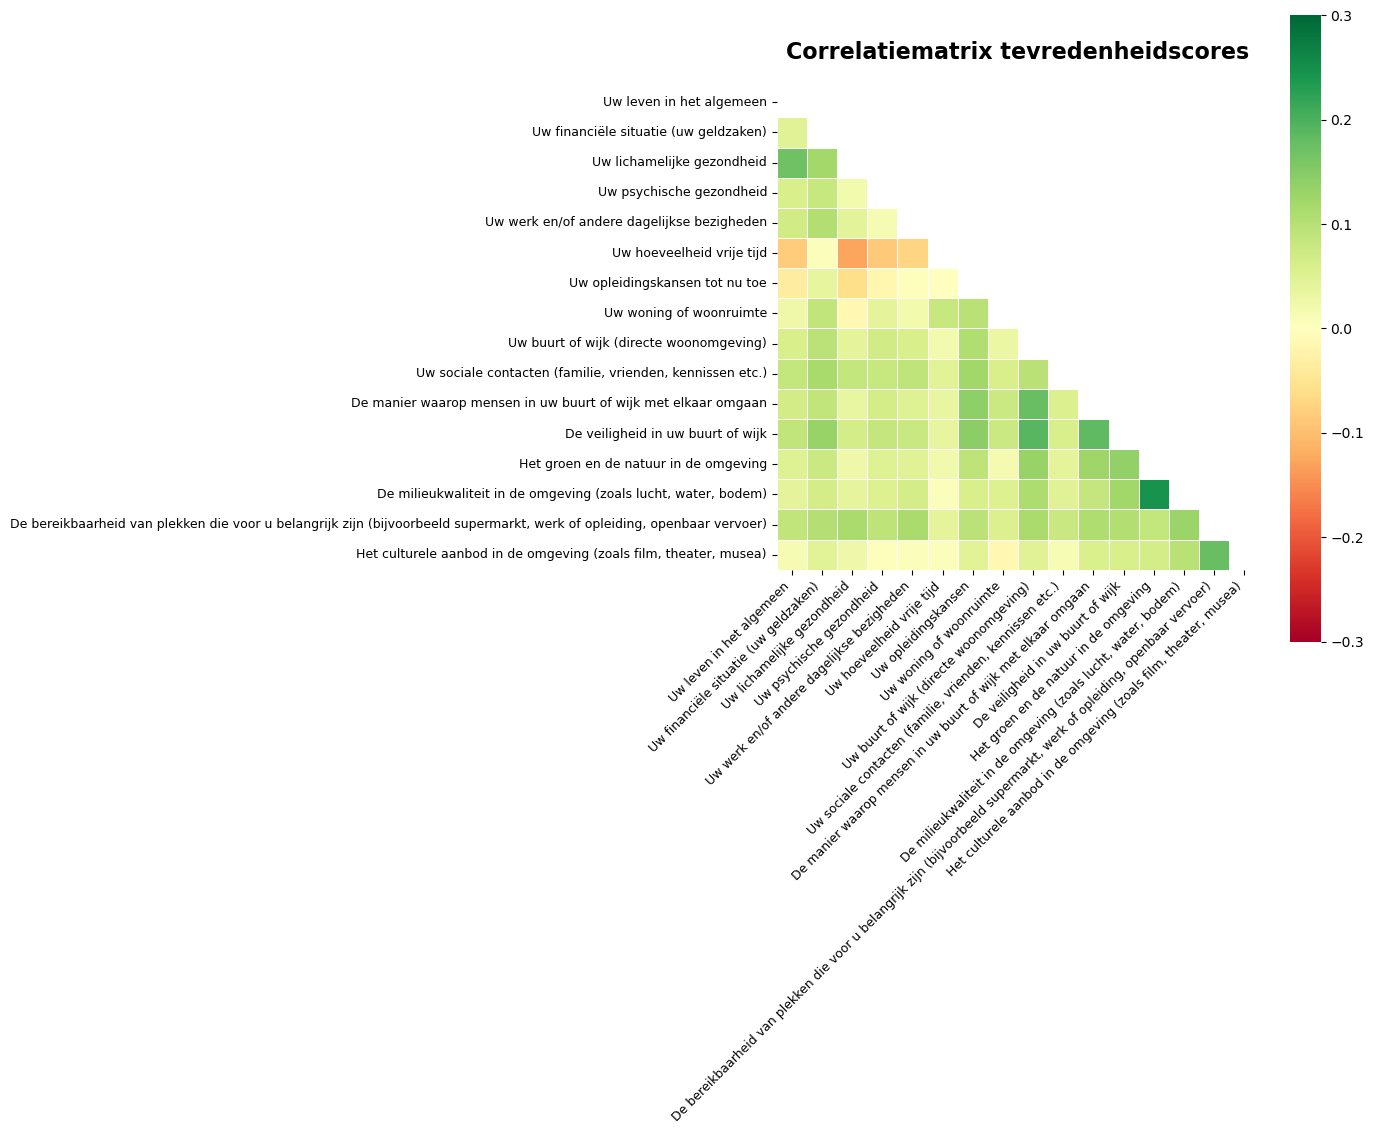

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

fig, ax = plt.subplots(figsize=(14, 12))

# Mask upper triangle for cleaner look
mask = np.triu(np.ones_like(corr_matrix_toekomst, dtype=bool))

sns.heatmap(
    corr_matrix_toekomst,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    center=0,
    vmin=-0.3, vmax=0.3,
    square=True,
    linewidths=0.5,
    linecolor="white",
    annot_kws={"size": 8},
    ax=ax
)

ax.set_title("Correlatiematrix tevredenheidscores", fontsize=16, fontweight="bold", pad=20)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontsize=9)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=9)

plt.tight_layout()
plt.savefig("correlatiematrix_tevredenheid.png", dpi=150, bbox_inches="tight")
plt.show()

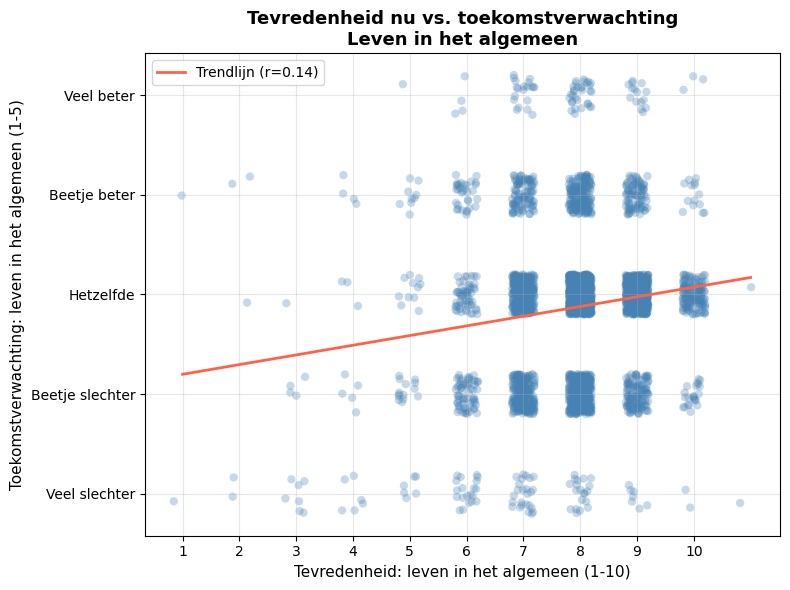

In [ ]:
import matplotlib.pyplot as plt

x = tevreden_df["Uw leven in het algemeen"]
y = toekomst_df["Uw leven in het algemeen"]

fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(x, y, alpha=0.3, edgecolors="none", color="steelblue")

# Add jitter to avoid overplotting on discrete scales
import numpy as np
x_jitter = x + np.random.uniform(-0.2, 0.2, size=len(x))
y_jitter = y + np.random.uniform(-0.2, 0.2, size=len(y))

ax.clear()
ax.scatter(x_jitter, y_jitter, alpha=0.3, edgecolors="none", color="steelblue")

# Trend line
mask = x.notna() & y.notna()
m, b = np.polyfit(x[mask], y[mask], 1)
x_line = np.linspace(x.min(), x.max(), 100)
ax.plot(x_line, m * x_line + b, color="tomato", linewidth=2, label=f"Trendlijn (r={x[mask].corr(y[mask]):.2f})")

ax.set_xlabel("Tevredenheid: leven in het algemeen (1-10)", fontsize=11)
ax.set_ylabel("Toekomstverwachting: leven in het algemeen (1-5)", fontsize=11)
ax.set_title("Tevredenheid nu vs. toekomstverwachting\nLeven in het algemeen", fontsize=13, fontweight="bold")
ax.set_xticks(range(1, 11))
ax.set_yticks(range(1, 6))
ax.yaxis.set_ticklabels(["Veel slechter", "Beetje slechter", "Hetzelfde", "Beetje beter", "Veel beter"])
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("scatter_leven_tevredenheid_toekomst.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
# Subjects that appear in both tevredenheid and toekomst
subjects = [col for col in tevreden_df.columns if col in toekomst_df.columns]

for subject in subjects:
    tev = tevreden_df[subject]
    toe = toekomst_df[subject]

    conditions = [
    (tev >= 7) & (toe >= 3),   # tevreden & stabiel of beter
    (tev >= 7) & (toe < 3),    # tevreden & pessimistisch
    (tev < 7)  & (toe >= 3),   # ontevreden & stabiel of beter/optimistisch
    (tev < 7)  & (toe < 3),    # ontevreden & pessimistisch
]
    labels = ["tevreden_en_stabiel", "tevreden_en_pessimistisch", "ontevreden_en_optimistisch", "ontevreden_en_pessimistisch"]

    col_name = f"situatie_{subject.lower().replace(' ', '_').replace('/', '_')[:40]}"
    df[col_name] = np.select(conditions, labels, default=np.nan)

# Check result
situatie_cols = [col for col in df.columns if col.startswith("situatie_")]


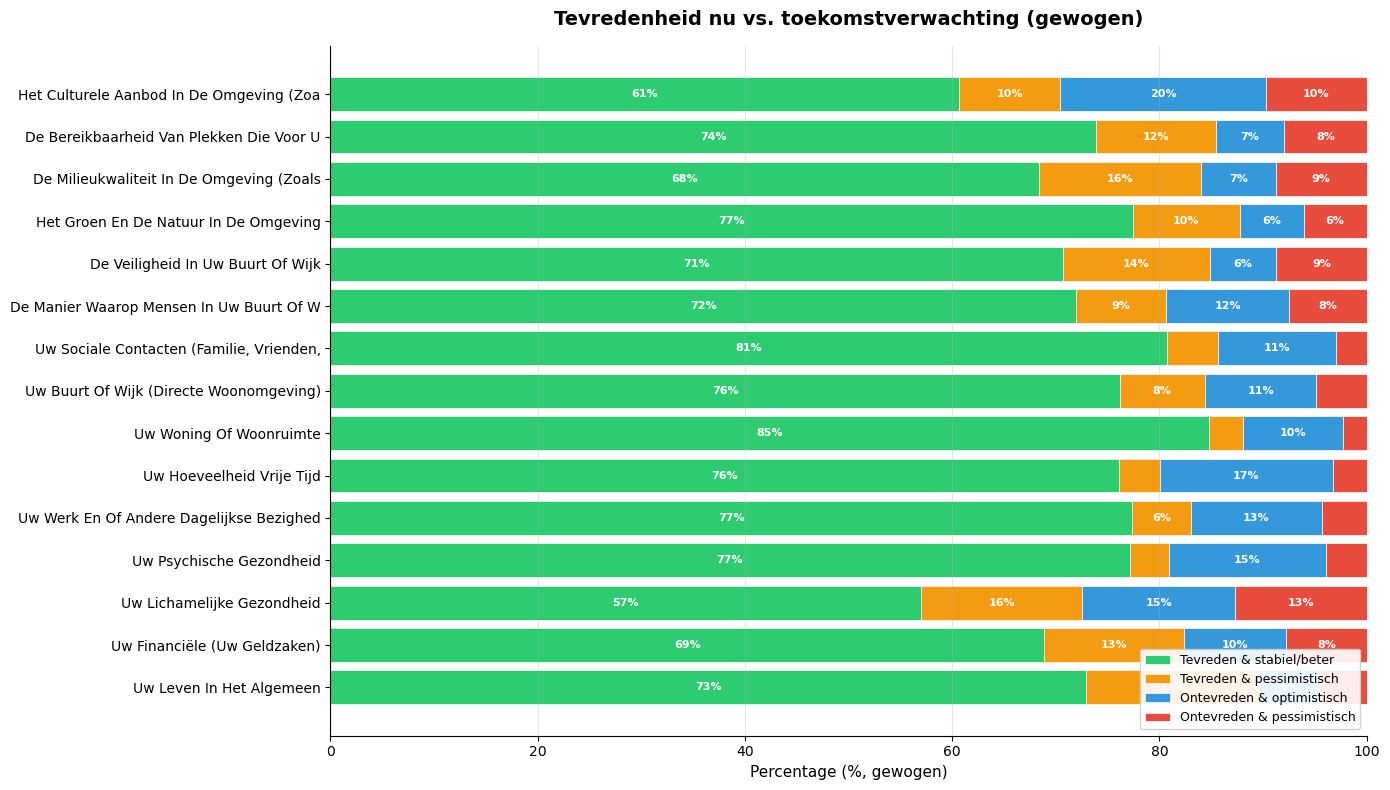

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

weight_col = "Weegfactor_GRDR"

# Compute weighted proportions per subject
records = []
for col in situatie_cols:
    sub = df[[col, weight_col]].dropna(subset=[col, weight_col])
    weighted_counts = sub.groupby(col)[weight_col].sum()
    weighted_pct = weighted_counts / weighted_counts.sum() * 100
    weighted_pct.name = col.replace("situatie_", "").replace("_", " ").title()
    records.append(weighted_pct)

prop_df = pd.DataFrame(records).fillna(0)


cat_order = ["tevreden_en_stabiel", "tevreden_en_pessimistisch", "ontevreden_en_optimistisch", "ontevreden_en_pessimistisch"]

# Consistent column order
prop_df = prop_df[[c for c in cat_order if c in prop_df.columns]]
prop_df = prop_df.div(prop_df.sum(axis=1), axis=0) * 100

colors = {
    "tevreden_en_stabiel":         "#2ecc71",
    "tevreden_en_pessimistisch":   "#f39c12",
    "ontevreden_en_optimistisch":  "#3498db",
    "ontevreden_en_pessimistisch": "#e74c3c",
}
labels_map = {
    "tevreden_en_stabiel":         "Tevreden & stabiel/beter",
    "tevreden_en_pessimistisch":   "Tevreden & pessimistisch",
    "ontevreden_en_optimistisch":  "Ontevreden & optimistisch",
    "ontevreden_en_pessimistisch": "Ontevreden & pessimistisch",
}

fig, ax = plt.subplots(figsize=(14, 8))

left = np.zeros(len(prop_df))
for cat in cat_order:
    if cat not in prop_df.columns:
        continue
    ax.barh(
        prop_df.index,
        prop_df[cat],
        left=left,
        color=colors[cat],
        label=labels_map[cat],
        edgecolor="white",
        linewidth=0.5,
    )
    for i, (val, l) in enumerate(zip(prop_df[cat], left)):
        if val > 5:
            ax.text(l + val / 2, i, f"{val:.0f}%", ha="center", va="center",
                    fontsize=8, color="white", fontweight="bold")
    left += prop_df[cat].values

ax.set_xlim(0, 100)
ax.set_xlabel("Percentage (%, gewogen)", fontsize=11)
ax.set_title("Tevredenheid nu vs. toekomstverwachting (gewogen)", 
             fontsize=14, fontweight="bold", pad=15)
ax.legend(loc="lower right", fontsize=9, framealpha=0.9)
ax.grid(axis="x", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("stacked_bar_situatie_gewogen.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
# Keep only the first occurrence of any duplicate column name
df = df.loc[:, ~df.columns.duplicated()]

print(f"Shape na dedupe: {df.shape}")
print("Resterende duplicaten:", df.columns.duplicated().sum())

Shape na dedupe: (4265, 315)
Resterende duplicaten: 0


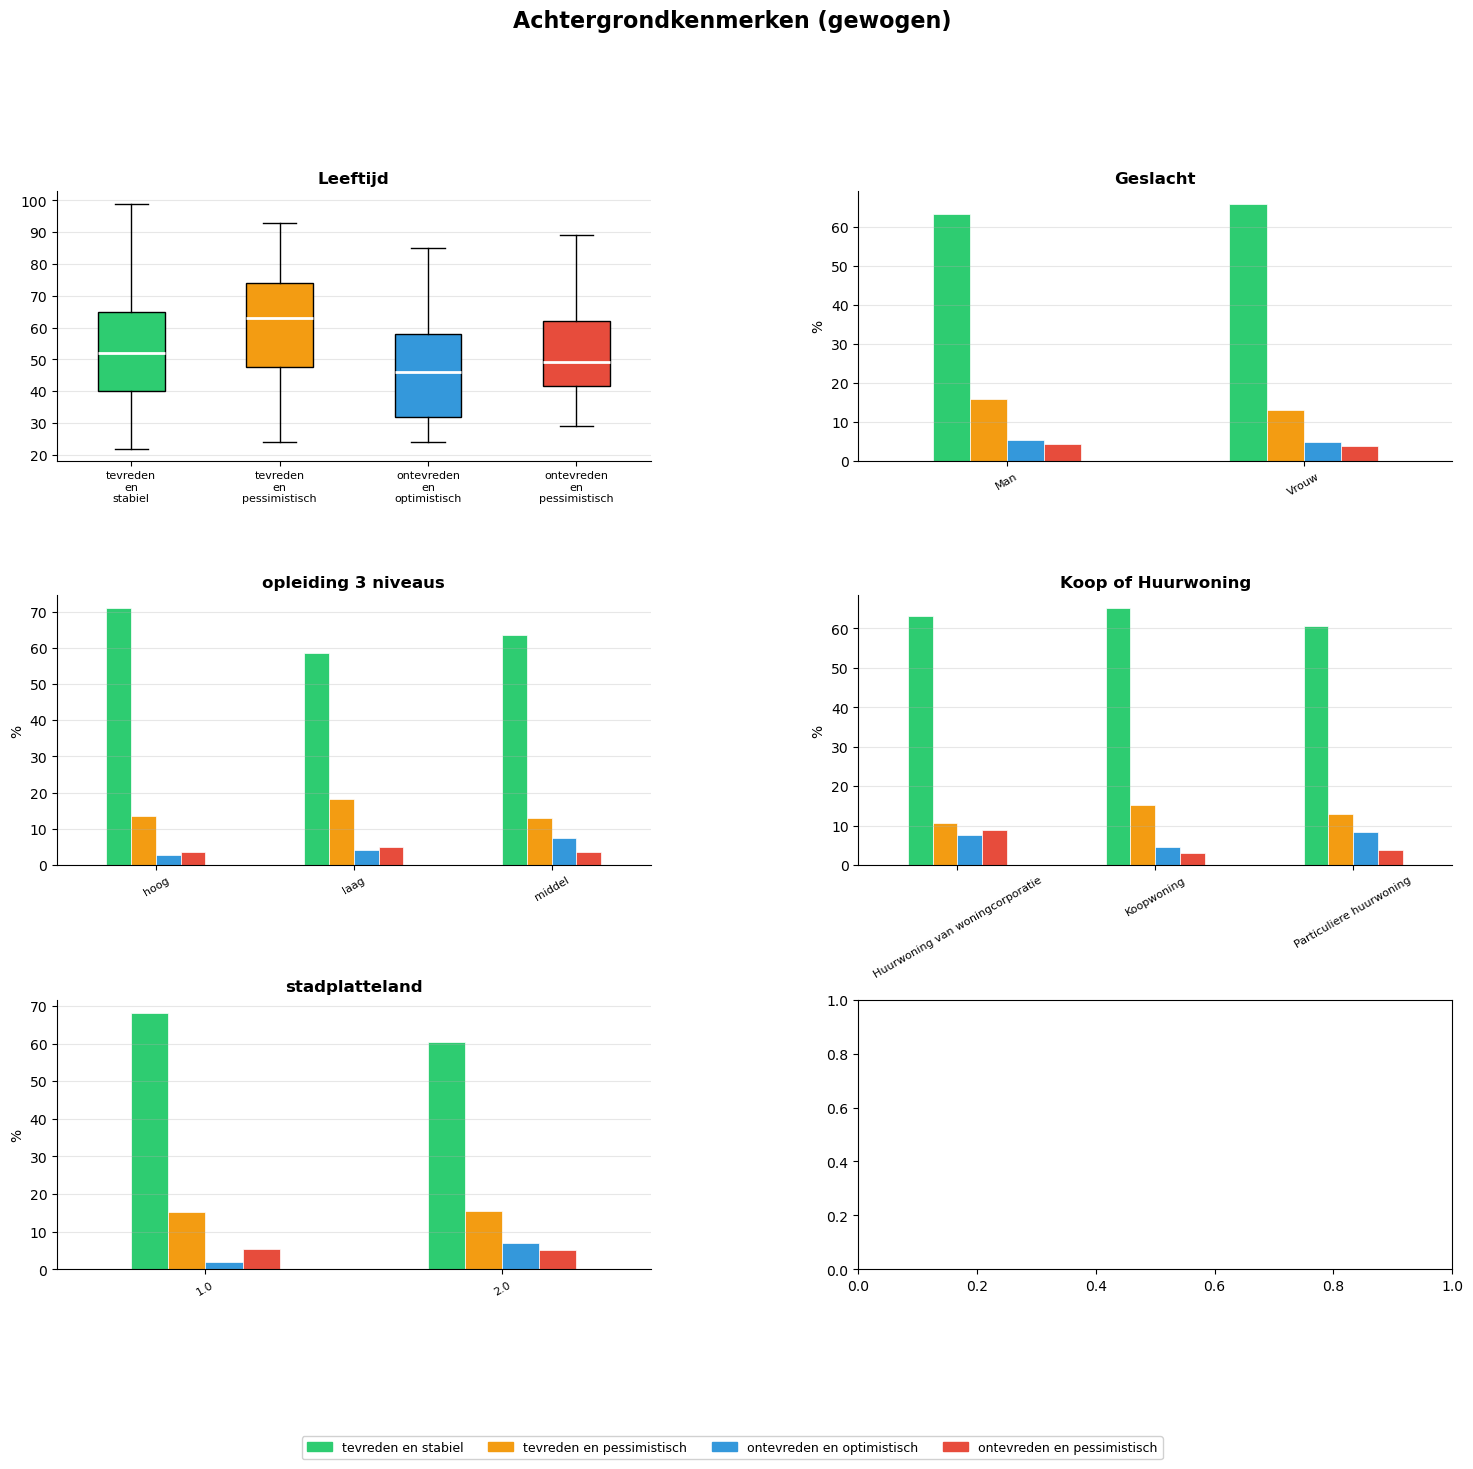

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd

situatie_leven = "situatie_uw_leven_in_het_algemeen"
weight_col = "Weegfactor_GRDR"
background_vars = [v for v in ["Leeftijd", "Geslacht", "opleiding 3 niveaus",
                                "Inkomen in 3 categorieÃ«n", "Koop of Huurwoning", "stadplatteland"]
                    if v in df.columns]
cat_vars = [v for v in background_vars if v != "Leeftijd"]
desc_df = df[[situatie_leven] + background_vars + [weight_col]].dropna(subset=[situatie_leven])

cat_order = ["tevreden_en_stabiel", "tevreden_en_pessimistisch", "ontevreden_en_optimistisch", "ontevreden_en_pessimistisch"]
colors_groep = {"tevreden_en_stabiel": "#2ecc71", "tevreden_en_pessimistisch": "#f39c12",
                "ontevreden_en_optimistisch": "#3498db", "ontevreden_en_pessimistisch": "#e74c3c"}

def wq(v, w, q):  # weighted quantile
    v, w = np.asarray(v, float), np.asarray(w, float)
    o = np.argsort(v); v, w = v[o], w[o]
    cw = (np.cumsum(w) - 0.5 * w) / w.sum()
    return np.interp(q, cw, v)

fig = plt.figure(figsize=(18, 14))
fig.suptitle("Achtergrondkenmerken (gewogen)", fontsize=16, fontweight="bold", y=1.01)
gs = gridspec.GridSpec(3, 2, figure=fig, hspace=0.5, wspace=0.35)
axes = [fig.add_subplot(gs[i, j]) for i in range(3) for j in range(2)]

# Leeftijd: gewogen boxplot
ax = axes[0]
stats = []
for g in cat_order:
    sub = desc_df[desc_df[situatie_leven] == g][["Leeftijd", weight_col]].dropna()
    v, w = sub["Leeftijd"].values, sub[weight_col].values
    q1, med, q3 = wq(v, w, 0.25), wq(v, w, 0.5), wq(v, w, 0.75)
    stats.append({"med": med, "q1": q1, "q3": q3, "whislo": v.min(), "whishi": v.max(), "fliers": []})
bp = ax.bxp(stats, patch_artist=True, medianprops=dict(color="white", linewidth=2))
for patch, g in zip(bp["boxes"], cat_order):
    patch.set_facecolor(colors_groep[g])
ax.set_xticklabels([g.replace("_", "\n") for g in cat_order], fontsize=8)
ax.set_title("Leeftijd", fontweight="bold")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)

# Categorische vars: gewogen grouped bar charts
for idx, var in enumerate(cat_vars):
    ax = axes[idx + 1]
    sub = desc_df[[situatie_leven, var, weight_col]].dropna()
    ct = sub.groupby([situatie_leven, var])[weight_col].sum().unstack(fill_value=0)
    ct = (ct / ct.sum() * 100).reindex(cat_order).dropna(how="all")
    ct.T.plot(kind="bar", ax=ax, color=[colors_groep[g] for g in ct.index],
              edgecolor="white", linewidth=0.5, legend=False)
    ax.set_title(var, fontweight="bold")
    ax.set_ylabel("%")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30, labelsize=8)
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

handles = [plt.Rectangle((0, 0), 1, 1, color=colors_groep[g]) for g in cat_order]
fig.legend(handles, [g.replace("_", " ") for g in cat_order], loc="lower center", ncol=4,
           fontsize=9, bbox_to_anchor=(0.5, -0.03), framealpha=0.9)

plt.savefig("descriptives_situatie_leven_gewogen.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd

situatie_leven = "situatie_veiligheid"
weight_col = "Weegfactor_GRDR"
background_vars = [v for v in ["Leeftijd", "Geslacht", "opleiding 3 niveaus",
                                "Inkomen in 3 categorieÃ«n", "Koop of Huurwoning", "stadplatteland"]
                    if v in df.columns]
cat_vars = [v for v in background_vars if v != "Leeftijd"]
desc_df = df[[situatie_leven] + background_vars + [weight_col]].dropna(subset=[situatie_leven])

cat_order = ["tevreden_en_stabiel", "tevreden_en_pessimistisch", "ontevreden_en_optimistisch", "ontevreden_en_pessimistisch"]
colors_groep = {"tevreden_en_stabiel": "#2ecc71", "tevreden_en_pessimistisch": "#f39c12",
                "ontevreden_en_optimistisch": "#3498db", "ontevreden_en_pessimistisch": "#e74c3c"}

def wq(v, w, q):  # weighted quantile
    v, w = np.asarray(v, float), np.asarray(w, float)
    o = np.argsort(v); v, w = v[o], w[o]
    cw = (np.cumsum(w) - 0.5 * w) / w.sum()
    return np.interp(q, cw, v)

fig = plt.figure(figsize=(18, 14))
fig.suptitle("Achtergrondkenmerken (gewogen)", fontsize=16, fontweight="bold", y=1.01)
gs = gridspec.GridSpec(3, 2, figure=fig, hspace=0.5, wspace=0.35)
axes = [fig.add_subplot(gs[i, j]) for i in range(3) for j in range(2)]

# Leeftijd: gewogen boxplot
ax = axes[0]
stats = []
for g in cat_order:
    sub = desc_df[desc_df[situatie_leven] == g][["Leeftijd", weight_col]].dropna()
    v, w = sub["Leeftijd"].values, sub[weight_col].values
    q1, med, q3 = wq(v, w, 0.25), wq(v, w, 0.5), wq(v, w, 0.75)
    stats.append({"med": med, "q1": q1, "q3": q3, "whislo": v.min(), "whishi": v.max(), "fliers": []})
bp = ax.bxp(stats, patch_artist=True, medianprops=dict(color="white", linewidth=2))
for patch, g in zip(bp["boxes"], cat_order):
    patch.set_facecolor(colors_groep[g])
ax.set_xticklabels([g.replace("_", "\n") for g in cat_order], fontsize=8)
ax.set_title("Leeftijd", fontweight="bold")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)

# Categorische vars: gewogen grouped bar charts
for idx, var in enumerate(cat_vars):
    ax = axes[idx + 1]
    sub = desc_df[[situatie_leven, var, weight_col]].dropna()
    ct = sub.groupby([situatie_leven, var])[weight_col].sum().unstack(fill_value=0)
    ct = (ct / ct.sum() * 100).reindex(cat_order).dropna(how="all")
    ct.T.plot(kind="bar", ax=ax, color=[colors_groep[g] for g in ct.index],
              edgecolor="white", linewidth=0.5, legend=False)
    ax.set_title(var, fontweight="bold")
    ax.set_ylabel("%")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30, labelsize=8)
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

handles = [plt.Rectangle((0, 0), 1, 1, color=colors_groep[g]) for g in cat_order]
fig.legend(handles, [g.replace("_", " ") for g in cat_order], loc="lower center", ncol=4,
           fontsize=9, bbox_to_anchor=(0.5, -0.03), framealpha=0.9)

plt.savefig("descriptives_situatie_leven_gewogen.png", dpi=150, bbox_inches="tight")
plt.show()

KeyError: "['situatie_veiligheid'] not in index"

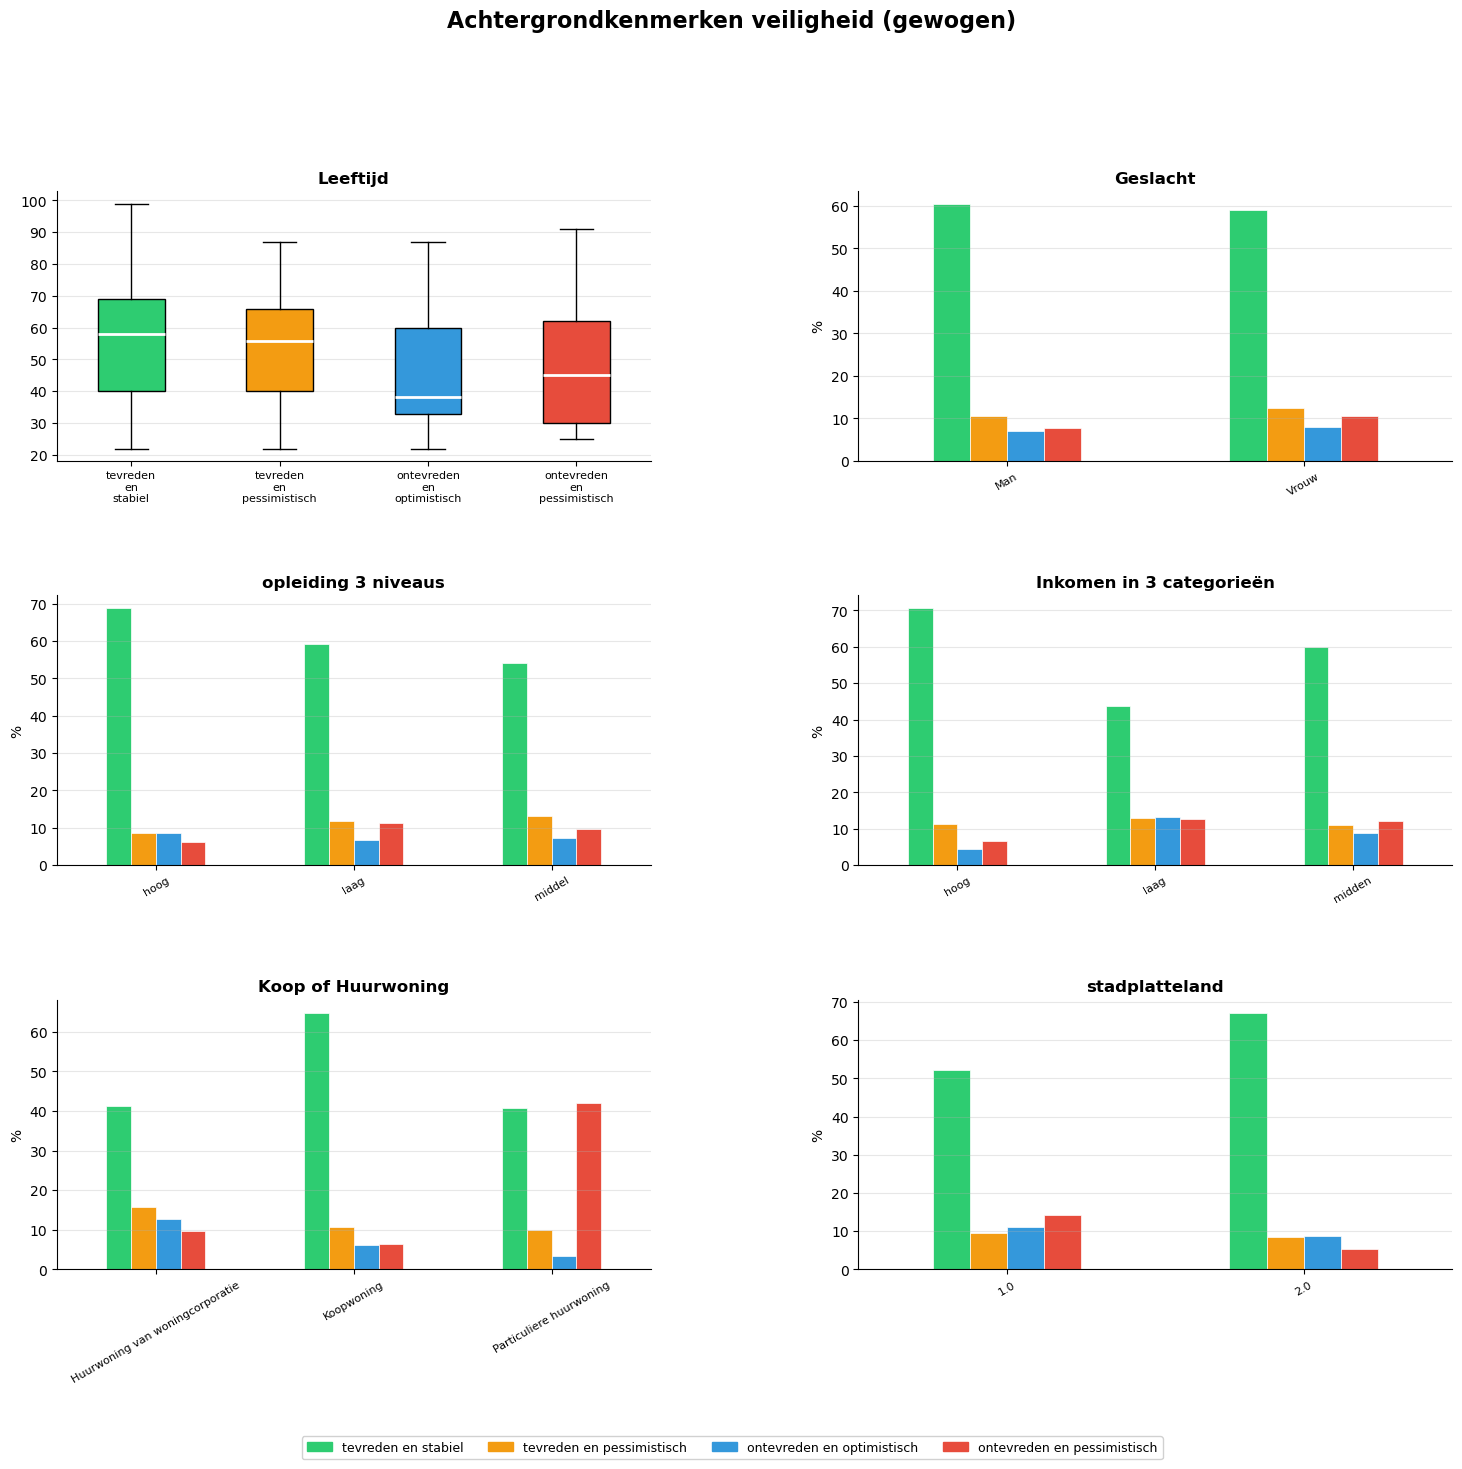

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd

situatie_leven = "situatie_de_veiligheid_in_uw_buurt_of_wijk"
weight_col = "Weegfactor_GRDR"
background_vars = [v for v in ["Leeftijd", "Geslacht", "opleiding 3 niveaus",
                                "Inkomen in 3 categorieën", "Koop of Huurwoning", "stadplatteland"]
                    if v in df.columns]
cat_vars = [v for v in background_vars if v != "Leeftijd"]
desc_df = df[[situatie_leven] + background_vars + [weight_col]].dropna(subset=[situatie_leven])

cat_order = ["tevreden_en_stabiel", "tevreden_en_pessimistisch", "ontevreden_en_optimistisch", "ontevreden_en_pessimistisch"]
colors_groep = {"tevreden_en_stabiel": "#2ecc71", "tevreden_en_pessimistisch": "#f39c12",
                "ontevreden_en_optimistisch": "#3498db", "ontevreden_en_pessimistisch": "#e74c3c"}

def wq(v, w, q):
    v, w = np.asarray(v, float), np.asarray(w, float)
    o = np.argsort(v); v, w = v[o], w[o]
    cw = (np.cumsum(w) - 0.5 * w) / w.sum()
    return np.interp(q, cw, v)

fig = plt.figure(figsize=(18, 14))
fig.suptitle("Achtergrondkenmerken veiligheid (gewogen)", fontsize=16, fontweight="bold", y=1.01)
gs = gridspec.GridSpec(3, 2, figure=fig, hspace=0.5, wspace=0.35)
axes = [fig.add_subplot(gs[i, j]) for i in range(3) for j in range(2)]

ax = axes[0]
stats = []
for g in cat_order:
    sub = desc_df[desc_df[situatie_leven] == g][["Leeftijd", weight_col]].dropna()
    v, w = sub["Leeftijd"].values, sub[weight_col].values
    q1, med, q3 = wq(v, w, 0.25), wq(v, w, 0.5), wq(v, w, 0.75)
    stats.append({"med": med, "q1": q1, "q3": q3, "whislo": v.min(), "whishi": v.max(), "fliers": []})
bp = ax.bxp(stats, patch_artist=True, medianprops=dict(color="white", linewidth=2))
for patch, g in zip(bp["boxes"], cat_order):
    patch.set_facecolor(colors_groep[g])
ax.set_xticklabels([g.replace("_", "\n") for g in cat_order], fontsize=8)
ax.set_title("Leeftijd", fontweight="bold")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)

for idx, var in enumerate(cat_vars):
    ax = axes[idx + 1]
    sub = desc_df[[situatie_leven, var, weight_col]].dropna()
    ct = sub.groupby([situatie_leven, var])[weight_col].sum().unstack(fill_value=0)
    ct = (ct / ct.sum() * 100).reindex(cat_order).dropna(how="all")
    ct.T.plot(kind="bar", ax=ax, color=[colors_groep[g] for g in ct.index],
              edgecolor="white", linewidth=0.5, legend=False)
    ax.set_title(var, fontweight="bold")
    ax.set_ylabel("%")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30, labelsize=8)
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

handles = [plt.Rectangle((0, 0), 1, 1, color=colors_groep[g]) for g in cat_order]
fig.legend(handles, [g.replace("_", " ") for g in cat_order], loc="lower center", ncol=4,
           fontsize=9, bbox_to_anchor=(0.5, -0.03), framealpha=0.9)

plt.savefig("descriptives_situatie_veiligheid_gewogen.png", dpi=150, bbox_inches="tight")
plt.show()


In [ ]:
print([c for c in df.columns if c.startswith("situatie_")])

['situatie_uw_leven_in_het_algemeen', 'situatie_uw_financiële_situatie_(uw_geldzaken)', 'situatie_uw_lichamelijke_gezondheid', 'situatie_uw_psychische_gezondheid', 'situatie_uw_werk_en_of_andere_dagelijkse_bezighed', 'situatie_uw_hoeveelheid_vrije_tijd', 'situatie_uw_woning_of_woonruimte', 'situatie_uw_buurt_of_wijk_(directe_woonomgeving)', 'situatie_uw_sociale_contacten_(familie,_vrienden,', 'situatie_de_manier_waarop_mensen_in_uw_buurt_of_w', 'situatie_de_veiligheid_in_uw_buurt_of_wijk', 'situatie_het_groen_en_de_natuur_in_de_omgeving', 'situatie_de_milieukwaliteit_in_de_omgeving_(zoals', 'situatie_de_bereikbaarheid_van_plekken_die_voor_u', 'situatie_het_culturele_aanbod_in_de_omgeving_(zoa']


In [ ]:
import pandas as pd

invloed_cols = [c for c in df.columns if "hoeveel invloed" in c.lower()]

invloed_dummy_cols = []
for c in invloed_cols:
    subject = c.split(" - ")[-1].strip()
    dummy_name = f"{subject}_invloed"
    df[dummy_name] = df[c].astype(str).str.lower().str.contains("veel|beetje", na=False, regex=True).astype(int)
    df.loc[df[c].isna(), dummy_name] = pd.NA
    invloed_dummy_cols.append(dummy_name)

# â”€â”€ Check: does the dummy match expectations? â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
for c, d in zip(invloed_cols, invloed_dummy_cols):
    print(f"\n=== {c} -> {d} ===")
    print(pd.crosstab(df[c], df[d], dropna=False))


=== Hoeveel invloed denkt u dat u heeft op: - Uw leven in het algemeen -> Uw leven in het algemeen_invloed ===
Uw leven in het algemeen_invloed                    0.0   1.0  NaN
Hoeveel invloed denkt u dat u heeft op: - Uw le...                
Een beetje invloed                                    0  1679    0
Geen invloed                                        185     0    0
Veel invloed                                          0  2026    0
Weet ik niet                                         86     0    0
NaN                                                   0     0  289

=== Hoeveel invloed denkt u dat u heeft op: - Uw financiÃ«le situatie (uw geldzaken) -> Uw financiÃ«le situatie (uw geldzaken)_invloed ===
Uw financiÃ«le situatie (uw geldzaken)_invloed       0.0   1.0  NaN
Hoeveel invloed denkt u dat u heeft op: - Uw fi...                
Een beetje invloed                                    0  1905    0
Geen invloed                                        727     0    0
Veel invlo

Doelvariabele: Uw leven in het algemeen
Predictor-subjects: ['Uw financiÃ«le situatie (uw geldzaken)', 'Uw lichamelijke gezondheid', 'Uw psychische gezondheid', 'Uw werk en/of andere dagelijkse bezigheden', 'Uw hoeveelheid vrije tijd', 'Uw woning of woonruimte', 'Uw buurt of wijk (directe woonomgeving)', 'Uw sociale contacten (familie, vrienden, kennissen etc.)', 'De manier waarop mensen in uw buurt of wijk met elkaar omgaan', 'De veiligheid in uw buurt of wijk', 'Het groen en de natuur in de omgeving', 'De milieukwaliteit in de omgeving (zoals lucht, water, bodem)', 'De bereikbaarheid van plekken die voor u belangrijk zijn (bijvoorbeeld supermarkt, werk of opleiding, openbaar vervoer)', 'Het culturele aanbod in de omgeving (zoals film, theater, musea)']

N vÃ³Ã³r imputatie (na dropna op target): 4126

Missende waarden per predictor (vÃ³Ã³r imputatie):
Leeftijd                                                                                                                            305

c:\Users\mkooistra\AppData\Local\anaconda3\Lib\site-packages\shap\plots\_beeswarm.py:950: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  pl.tight_layout()
C:\Users\mkooistra\AppData\Local\Temp\58\ipykernel_32384\4154965420.py:56: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


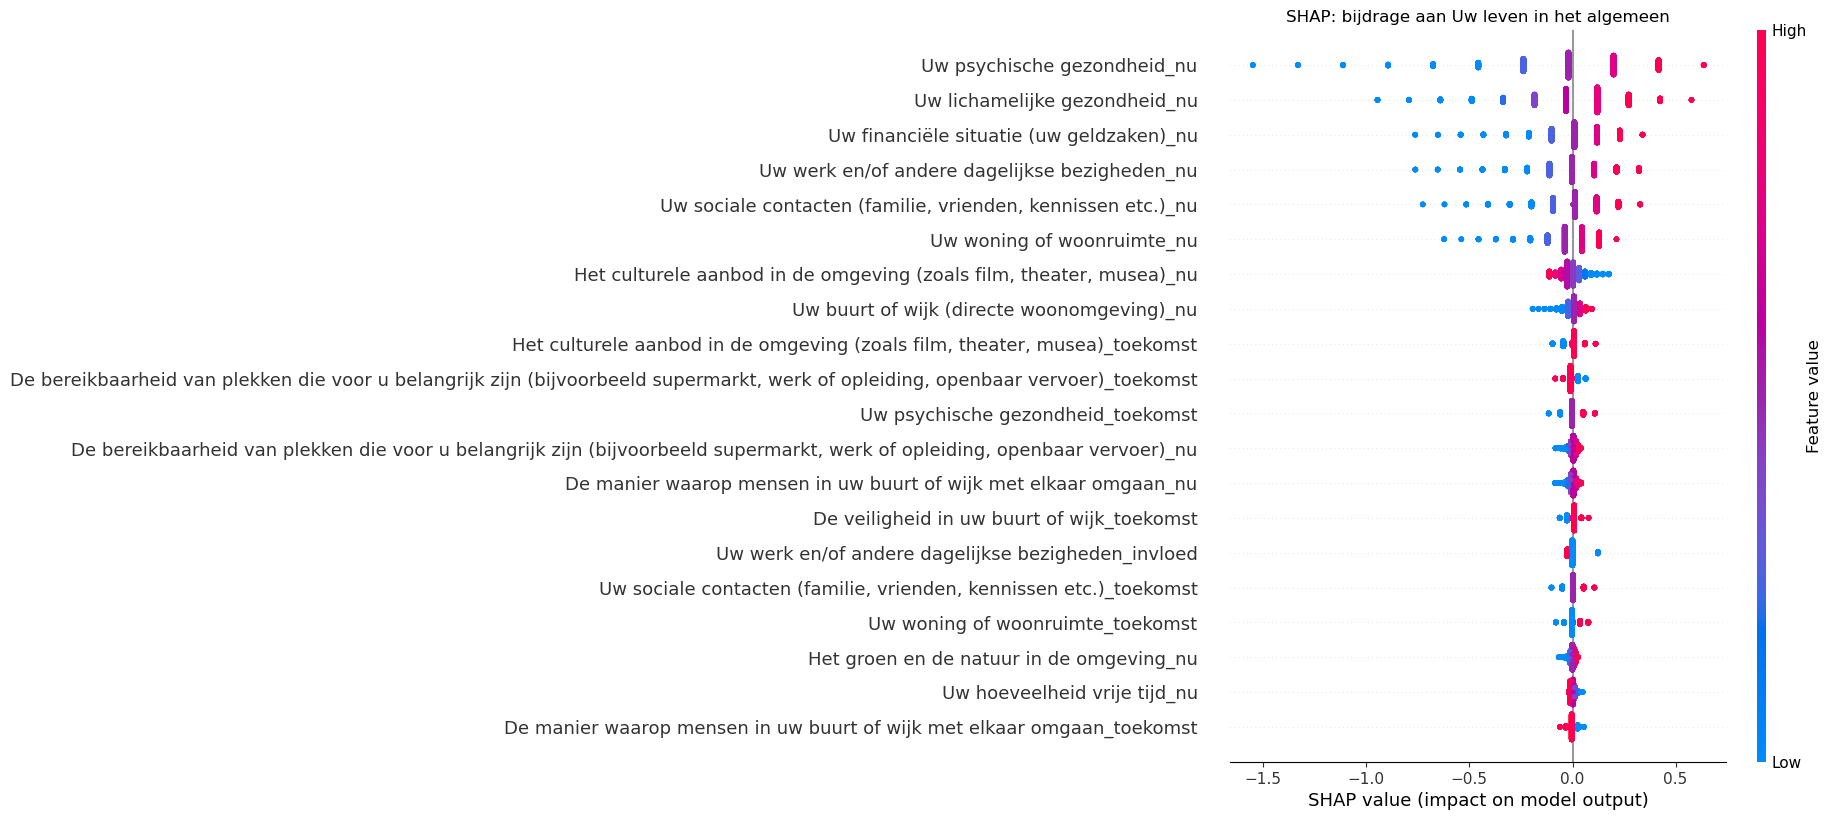


Gemiddelde |SHAP-waarde| per feature:
Uw psychische gezondheid_nu                                                                                                         0.226285
Uw lichamelijke gezondheid_nu                                                                                                       0.174587
Uw financiÃ«le situatie (uw geldzaken)_nu                                                                                            0.107865
Uw werk en/of andere dagelijkse bezigheden_nu                                                                                       0.104785
Uw sociale contacten (familie, vrienden, kennissen etc.)_nu                                                                         0.094723
Uw woning of woonruimte_nu                                                                                                          0.081308
Het culturele aanbod in de omgeving (zoals film, theater, musea)_nu                                               

In [ ]:
import statsmodels.api as sm
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# â”€â”€ 1. Doelvariabele: tevredenheid nu, "leven in het algemeen" â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
target_subject = [c for c in tevreden_df.columns if "leven in het algemeen" in c.lower()]
assert len(target_subject) == 1, f"Verwachtte 1 match, kreeg: {target_subject}"
target_subject = target_subject[0]
print("Doelvariabele:", target_subject)

# â”€â”€ 2. Predictor-subjects: alle andere subjects (nu + toekomst), exclusief target â”€
predictor_subjects = [s for s in subjects if s != target_subject]
print("Predictor-subjects:", predictor_subjects)

# â”€â”€ 3. Regressiedataframe opbouwen â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
reg_df = pd.DataFrame({"score": tevreden_df[target_subject], "Leeftijd": df["Leeftijd"]})
for s in predictor_subjects:
    reg_df[f"{s}_nu"] = tevreden_df[s]
    reg_df[f"{s}_toekomst"] = toekomst_df[s]
for d in invloed_dummy_cols:
    reg_df[d] = df[d]

# Alleen rijen droppen waar de DOELVARIABELE mist â€” X wordt zo dadelijk geÃ¯mputeerd
reg_df = reg_df.dropna(subset=["score"])
print(f"\nN vÃ³Ã³r imputatie (na dropna op target): {len(reg_df)}")

# â”€â”€ 3b. Mean-imputatie voor missende predictoren â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
predictor_cols = [c for c in reg_df.columns if c != "score"]
n_missing_per_col = reg_df[predictor_cols].isna().sum()
print("\nMissende waarden per predictor (vÃ³Ã³r imputatie):")
print(n_missing_per_col[n_missing_per_col > 0])

reg_df[predictor_cols] = reg_df[predictor_cols].astype(float)
reg_df[predictor_cols] = reg_df[predictor_cols].fillna(reg_df[predictor_cols].mean())

print(f"\nN na imputatie: {len(reg_df)}")

# â”€â”€ 4. OLS regressie â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
X = reg_df.drop(columns="score")
y = reg_df["score"]

X_sm = sm.add_constant(X)
model = sm.OLS(y, X_sm).fit()
print(model.summary())

# â”€â”€ 5. SHAP decompositie â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
lr = LinearRegression().fit(X, y)
explainer = shap.LinearExplainer(lr, X)
shap_values = explainer(X)

shap.summary_plot(shap_values, X, show=False)
plt.title(f"SHAP: bijdrage aan {target_subject}")
plt.tight_layout()
plt.savefig("shap_summary_leven_algemeen.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nGemiddelde |SHAP-waarde| per feature:")
print(pd.Series(np.abs(shap_values.values).mean(axis=0), index=X.columns).sort_values(ascending=False))

Doelvariabele: Uw leven in het algemeen (toekomst)
Predictor-subjects: ['Uw financiÃ«le situatie (uw geldzaken)', 'Uw lichamelijke gezondheid', 'Uw psychische gezondheid', 'Uw werk en/of andere dagelijkse bezigheden', 'Uw hoeveelheid vrije tijd', 'Uw woning of woonruimte', 'Uw buurt of wijk (directe woonomgeving)', 'Uw sociale contacten (familie, vrienden, kennissen etc.)', 'De manier waarop mensen in uw buurt of wijk met elkaar omgaan', 'De veiligheid in uw buurt of wijk', 'Het groen en de natuur in de omgeving', 'De milieukwaliteit in de omgeving (zoals lucht, water, bodem)', 'De bereikbaarheid van plekken die voor u belangrijk zijn (bijvoorbeeld supermarkt, werk of opleiding, openbaar vervoer)', 'Het culturele aanbod in de omgeving (zoals film, theater, musea)']

N = 750
                            OLS Regression Results                            
Dep. Variable:                  score   R-squared:                       0.465
Model:                            OLS   Adj. R-squared:  

c:\Users\mkooistra\AppData\Local\anaconda3\Lib\site-packages\shap\plots\_beeswarm.py:950: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  pl.tight_layout()
C:\Users\mkooistra\AppData\Local\Temp\58\ipykernel_32384\1382115048.py:41: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


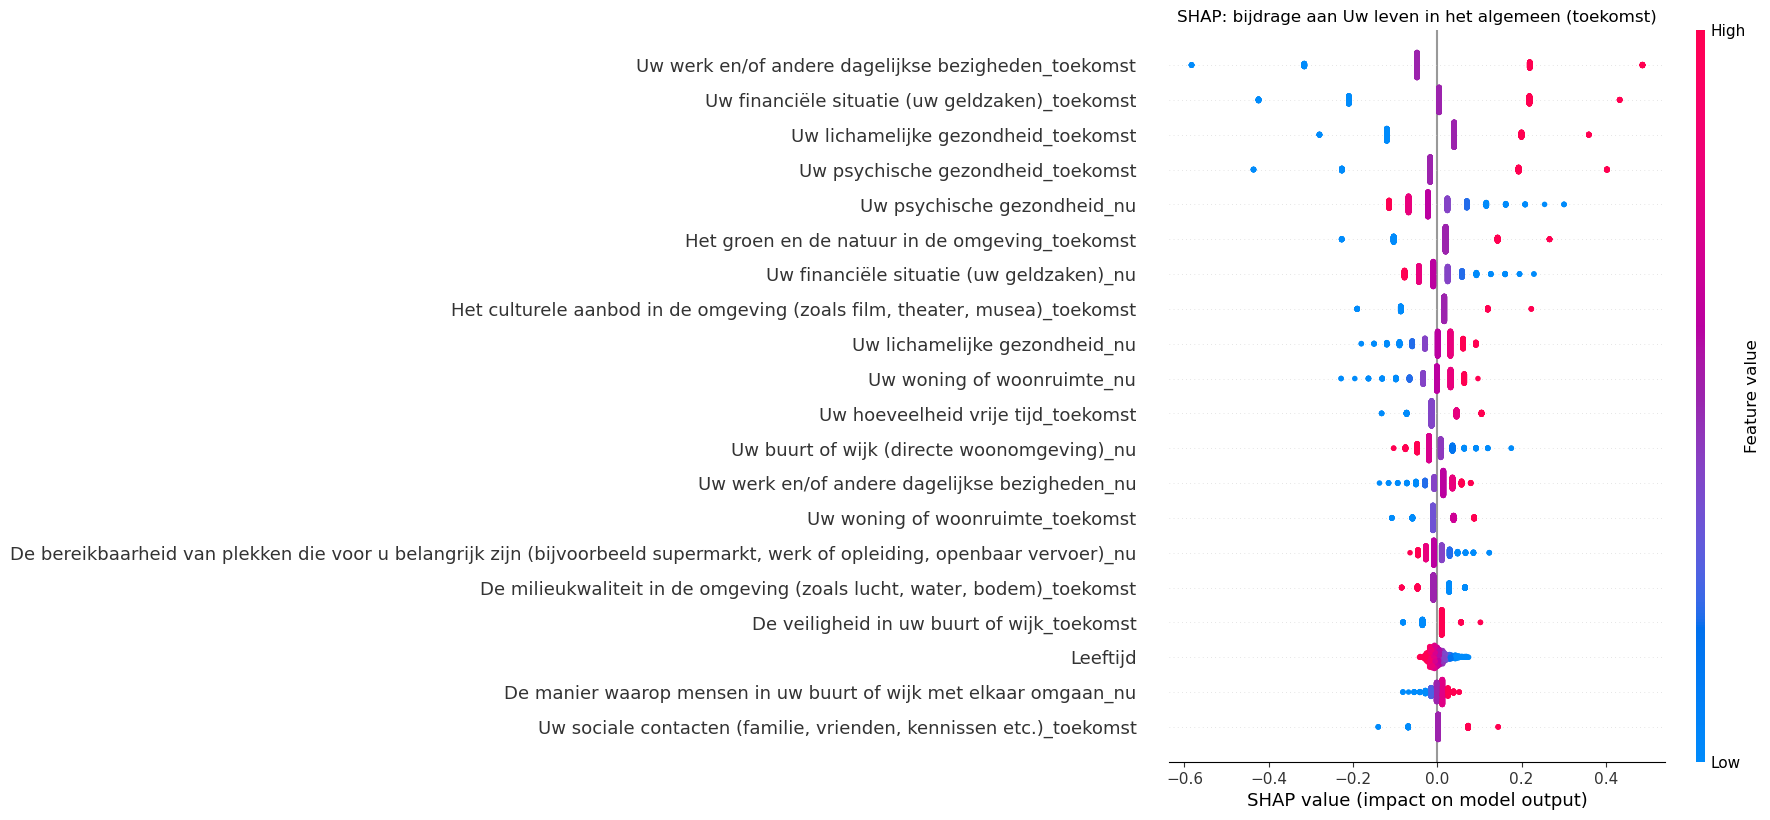


Gemiddelde |SHAP-waarde| per feature:
Uw werk en/of andere dagelijkse bezigheden_toekomst                                                                                 0.117149
Uw financiÃ«le situatie (uw geldzaken)_toekomst                                                                                      0.102081
Uw lichamelijke gezondheid_toekomst                                                                                                 0.089275
Uw psychische gezondheid_toekomst                                                                                                   0.066988
Uw psychische gezondheid_nu                                                                                                         0.057197
Het groen en de natuur in de omgeving_toekomst                                                                                      0.053731
Uw financiÃ«le situatie (uw geldzaken)_nu                                                                         

In [ ]:
import statsmodels.api as sm
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# â”€â”€ 1. Doelvariabele: toekomstverwachting, "leven in het algemeen" â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
target_subject = [c for c in toekomst_df.columns if "leven in het algemeen" in c.lower()]
assert len(target_subject) == 1, f"Verwachtte 1 match, kreeg: {target_subject}"
target_subject = target_subject[0]
print("Doelvariabele:", target_subject, "(toekomst)")

# â”€â”€ 2. Predictor-subjects: alle andere subjects (nu + toekomst), exclusief target â”€
predictor_subjects = [s for s in subjects if s != target_subject]
print("Predictor-subjects:", predictor_subjects)

# â”€â”€ 3. Regressiedataframe opbouwen â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
reg_df = pd.DataFrame({"score": toekomst_df[target_subject], "Leeftijd": df["Leeftijd"]})
for s in predictor_subjects:
    reg_df[f"{s}_nu"] = tevreden_df[s]
    reg_df[f"{s}_toekomst"] = toekomst_df[s]
reg_df = reg_df.dropna()
print(f"\nN = {len(reg_df)}")

# â”€â”€ 4. OLS regressie â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
X = reg_df.drop(columns="score").astype(float)
y = reg_df["score"]

X_sm = sm.add_constant(X)
model = sm.OLS(y, X_sm).fit()
print(model.summary())

# â”€â”€ 5. SHAP decompositie â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
lr = LinearRegression().fit(X, y)
explainer = shap.LinearExplainer(lr, X)
shap_values = explainer(X)

shap.summary_plot(shap_values, X, show=False)
plt.title(f"SHAP: bijdrage aan {target_subject} (toekomst)")
plt.tight_layout()
plt.savefig("shap_summary_leven_algemeen_toekomst.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nGemiddelde |SHAP-waarde| per feature:")
print(pd.Series(np.abs(shap_values.values).mean(axis=0), index=X.columns).sort_values(ascending=False))

In [ ]:
import pandas as pd

# â”€â”€ 1. Basic overview â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
print(f"Shape: {df.shape}")
print(f"\nAantal kolommen: {len(df.columns)}")

# â”€â”€ 2. Group columns by likely type/topic â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
dtype_counts = df.dtypes.value_counts()
print("\n=== Dtypes ===")
print(dtype_counts)

# â”€â”€ 3. Split into rough categories based on naming patterns â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
situatie_cols_here = [c for c in df.columns if c.startswith("situatie_")]
achtergrond_cols = ["Leeftijd", "Geslacht", "opleiding 3 niveaus", "Inkomen in 3 categorieÃ«n",
                     "Koop of Huurwoning", "stadplatteland", "gemeente", "dorpstype",
                     "Krimpgemeente", "regioprovincie"]
achtergrond_cols = [c for c in achtergrond_cols if c in df.columns]

tevredenheid_cols = [c for c in df.columns if "hoe tevreden u bent met" in c.lower()]
toekomst_cols = [c for c in df.columns if "komende 5 jaar" in c.lower()]
invloed_cols = [c for c in df.columns if "hoeveel invloed" in c.lower()]
hulp_netwerk_cols = [c for c in df.columns if "zou kunnen helpen met" in c.lower() or "terechtkunt" in c.lower()]
weet_waar_hulp_cols = [c for c in df.columns if "welke organisaties ik terecht kan" in c.lower()]
situaties_van_toepassing_cols = [c for c in df.columns if "situaties zijn op u van toepassing" in c.lower() or "situaties is op u van toepassing" in c.lower()]
stellingen_cols = [c for c in df.columns if "in hoeverre u het eens bent" in c.lower()]
open_vragen_cols = [c for c in df.columns if "open answers" in c.lower() or "toelichting" in c.lower() or "opmerkingen" in c.lower()]

print(f"\n=== CategorieÃ«n ===")
print(f"Achtergrondkenmerken: {len(achtergrond_cols)}")
print(f"Tevredenheid (nu): {len(tevredenheid_cols)}")
print(f"Toekomstverwachting: {len(toekomst_cols)}")
print(f"Ervaren invloed: {len(invloed_cols)}")
print(f"Sociaal netwerk / hulp: {len(hulp_netwerk_cols)}")
print(f"Weet waar hulp te vinden: {len(weet_waar_hulp_cols)}")
print(f"Situaties van toepassing (bestaanszekerheid): {len(situaties_van_toepassing_cols)}")
print(f"Stellingen (kansengelijkheid): {len(stellingen_cols)}")
print(f"Open vragen: {len(open_vragen_cols)}")
print(f"Al aangemaakte situatie_ kolommen: {len(situatie_cols_here)}")

geclassificeerd = (len(achtergrond_cols) + len(tevredenheid_cols) + len(toekomst_cols) +
                    len(invloed_cols) + len(hulp_netwerk_cols) + len(weet_waar_hulp_cols) +
                    len(situaties_van_toepassing_cols) + len(stellingen_cols) + len(open_vragen_cols) +
                    len(situatie_cols_here))
print(f"\nNog niet geclassificeerd: {len(df.columns) - geclassificeerd}")

# â”€â”€ 4. Missingness per categorie â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
print("\n=== % missing per categorie (gemiddeld) ===")
for naam, cols in [("Achtergrond", achtergrond_cols), ("Tevredenheid", tevredenheid_cols),
                    ("Toekomst", toekomst_cols), ("Invloed", invloed_cols),
                    ("Situaties bestaanszekerheid", situaties_van_toepassing_cols),
                    ("Stellingen", stellingen_cols)]:
    if cols:
        print(f"{naam}: {df[cols].isna().mean().mean()*100:.1f}%")

Shape: (4265, 325)

Aantal kolommen: 325

=== Dtypes ===
float64           174
object            148
datetime64[ns]      3
Name: count, dtype: int64

=== CategorieÃ«n ===
Achtergrondkenmerken: 10
Tevredenheid (nu): 16
Toekomstverwachting: 16
Ervaren invloed: 11
Sociaal netwerk / hulp: 14
Weet waar hulp te vinden: 9
Situaties van toepassing (bestaanszekerheid): 23
Stellingen (kansengelijkheid): 4
Open vragen: 16
Al aangemaakte situatie_ kolommen: 15

Nog niet geclassificeerd: 191

=== % missing per categorie (gemiddeld) ===
Achtergrond: 28.8%
Tevredenheid: 3.7%
Toekomst: 5.1%
Invloed: 6.8%
Situaties bestaanszekerheid: 0.0%
Stellingen: 8.0%


In [ ]:
import pandas as pd

hulp_netwerk_cols = [c for c in df.columns if "zou kunnen helpen met" in c.lower() or "terechtkunt" in c.lower()]
weet_waar_hulp_cols = [c for c in df.columns if "welke organisaties ik terecht kan" in c.lower()]
situaties_van_toepassing_cols = [c for c in df.columns if "situaties zijn op u van toepassing" in c.lower() or "situaties is op u van toepassing" in c.lower()]

for naam, cols in [("Sociaal netwerk / hulp", hulp_netwerk_cols),
                    ("Weet waar hulp te vinden", weet_waar_hulp_cols),
                    ("Situaties van toepassing (bestaanszekerheid)", situaties_van_toepassing_cols)]:
    print(f"\n{'='*80}\n{naam} ({len(cols)} kolommen)\n{'='*80}")
    for c in cols:
        print(f"\n--- {c} ---")
        print(df[c].value_counts(dropna=False).head(10))


Sociaal netwerk / hulp (14 kolommen)

--- Is er iemand (bijvoorbeeld een partner, familielid, vriend of kennis) die u zou kunnen helpen met: - Uw huishouden ---
Is er iemand (bijvoorbeeld een partner, familielid, vriend of kennis) die u zou kunnen helpen met: - Uw huishouden
Ja              2964
Nee              672
NaN              318
Weet ik niet     311
Name: count, dtype: int64

--- Is er iemand (bijvoorbeeld een partner, familielid, vriend of kennis) die u zou kunnen helpen met: - Uw boodschappen ---
Is er iemand (bijvoorbeeld een partner, familielid, vriend of kennis) die u zou kunnen helpen met: - Uw boodschappen
Ja              3292
Nee              439
NaN              318
Weet ik niet     216
Name: count, dtype: int64

--- Is er iemand (bijvoorbeeld een partner, familielid, vriend of kennis) die u zou kunnen helpen met: - Vervoer (bijvoorbeeld u met de auto ergens naartoe brengen) ---
Is er iemand (bijvoorbeeld een partner, familielid, vriend of kennis) die u zou kunnen hel

In [ ]:
weight_col = "Weegfactor_GRDR"

hulp_netwerk_cols = [c for c in df.columns if "zou kunnen helpen met" in c.lower() or "terechtkunt" in c.lower()]
weet_waar_hulp_cols = [c for c in df.columns if "welke organisaties ik terecht kan" in c.lower()]
situaties_van_toepassing_cols = [c for c in df.columns if "situaties zijn op u van toepassing" in c.lower() or "situaties is op u van toepassing" in c.lower()]

alle_cols = hulp_netwerk_cols + weet_waar_hulp_cols + situaties_van_toepassing_cols

bin_df = pd.DataFrame(index=df.index)
full_labels = {}

for c in alle_cols:
    if df[c].dropna().isin([0, 1]).all() or df[c].dtype == bool:
        vals = df[c].astype(float)
    else:
        vals = df[c].astype(str).str.lower().str.contains("ja", na=False, regex=False).astype(float)
        vals[df[c].isna()] = np.nan

    label = c.split(" - ")[-1].strip()
    if label in full_labels.values():
        label = f"{label} ({c.split('?')[0][:30]}...)"
    full_labels[c] = label
    bin_df[label] = vals

bin_df[weight_col] = df[weight_col]

def weighted_pct(col):
    sub = bin_df[[col, weight_col]].dropna()
    return np.average(sub[col], weights=sub[weight_col]) * 100

weighted_pcts = pd.Series(
    {label: weighted_pct(label) for label in full_labels.values()}
).sort_values(ascending=False)

print("=== Gewogen % 'ja'/geselecteerd per variabele ===")
print(weighted_pcts.round(1))

=== Gewogen % 'ja'/geselecteerd per variabele ===
Gezondheidszorg                                                                                                  94.7
Een luisterend oor / emotionele steun bieden                                                                     86.8
Mentale problemen (bijvoorbeeld stress, somberheid)                                                              85.0
Gezonder leven (bijvoorbeeld stoppen met roken of meer bewegen)                                                  85.0
Hulp van organisaties zoals de gemeente of de politie                                                            83.4
Uw boodschappen                                                                                                  82.7
Vervoer (bijvoorbeeld u met de auto ergens naartoe brengen)                                                      81.5
Het vinden van een (nieuwe) woning                                                                               77.9
Juridi

Doelvariabele: Uw leven in het algemeen (toekomst)

N vÃ³Ã³r imputatie (na dropna op target): 3830

Missende waarden per predictor (vÃ³Ã³r imputatie):
Leeftijd                                                                                                         2829
Uw huishouden                                                                                                    2889
Uw boodschappen                                                                                                  2889
Vervoer (bijvoorbeeld u met de auto ergens naartoe brengen)                                                      2889
Geld aan u te lenen                                                                                              2889
Een luisterend oor / emotionele steun bieden                                                                     2889
Een (tijdelijke) plek om te wonen                                                                                2889
Het overnemen van uw zo

c:\Users\mkooistra\AppData\Local\anaconda3\Lib\site-packages\shap\plots\_beeswarm.py:950: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  pl.tight_layout()
C:\Users\mkooistra\AppData\Local\Temp\58\ipykernel_32384\1645109601.py:80: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


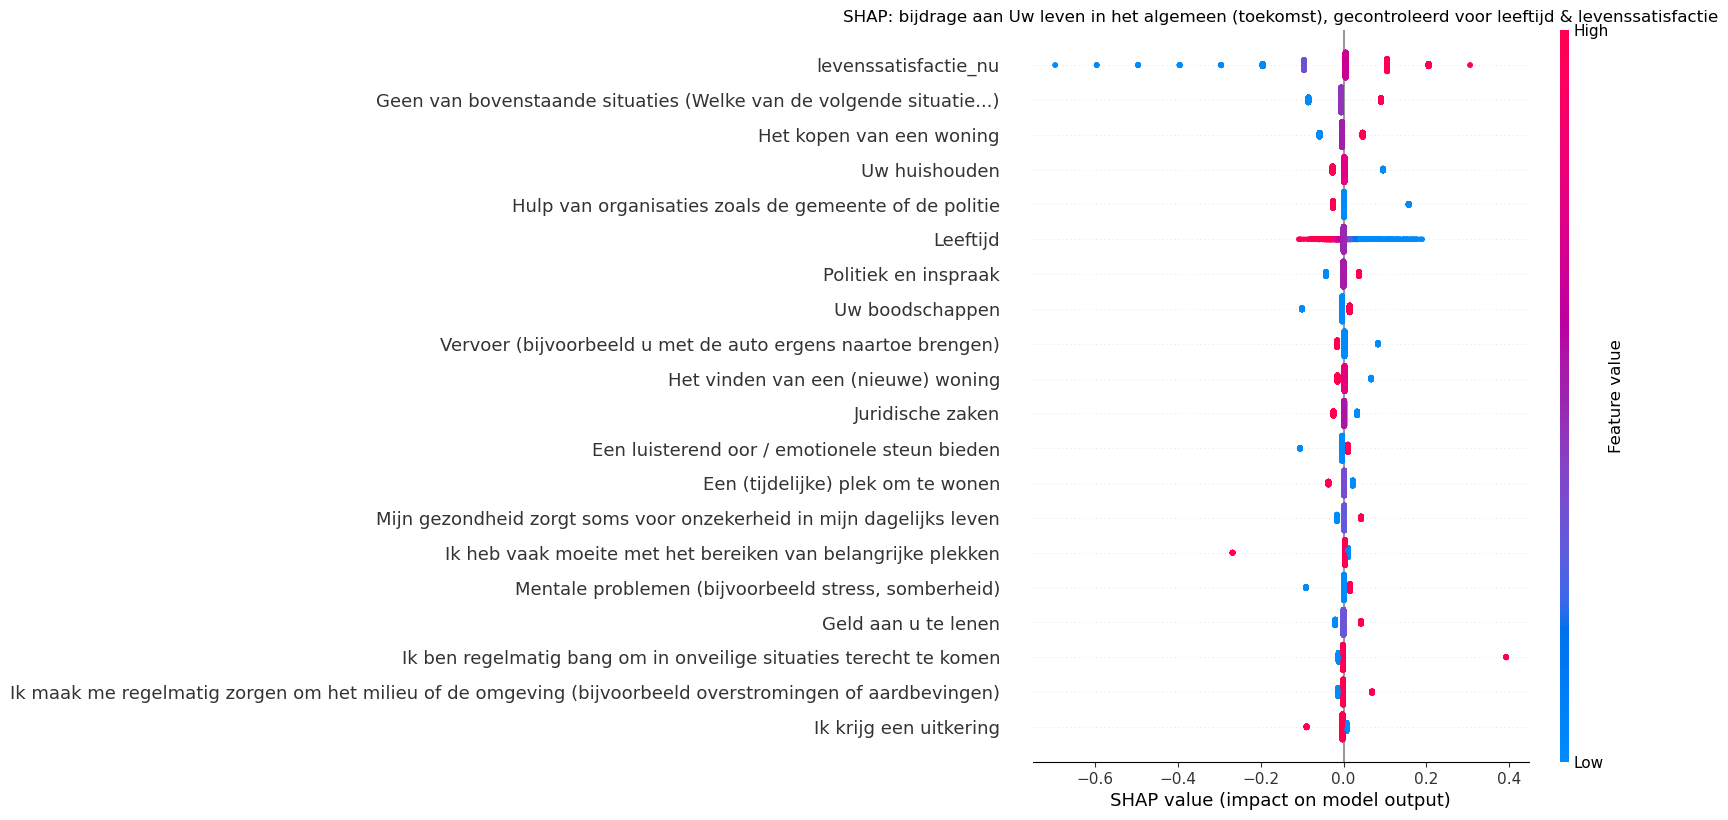


Gemiddelde |SHAP-waarde| per feature:
levenssatisfactie_nu                                                                                             0.071484
Geen van bovenstaande situaties (Welke van de volgende situatie...)                                              0.027641
Het kopen van een woning                                                                                         0.015471
Uw huishouden                                                                                                    0.011890
Hulp van organisaties zoals de gemeente of de politie                                                            0.011295
Leeftijd                                                                                                         0.010243
Politiek en inspraak                                                                                             0.009965
Uw boodschappen                                                                                            

In [ ]:
import statsmodels.api as sm
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# â”€â”€ 1. Doelvariabele: toekomstverwachting, "leven in het algemeen" â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
target_subject = [c for c in toekomst_df.columns if "leven in het algemeen" in c.lower()]
assert len(target_subject) == 1, f"Verwachtte 1 match, kreeg: {target_subject}"
target_subject = target_subject[0]
print("Doelvariabele:", target_subject, "(toekomst)")

# â”€â”€ 2. Life satisfaction nu, "leven in het algemeen" (controlevariabele) â”€â”€â”€â”€
tev_subject = [c for c in tevreden_df.columns if "leven in het algemeen" in c.lower()]
assert len(tev_subject) == 1
tev_subject = tev_subject[0]

# â”€â”€ 3. Onafhankelijke vars: hulp-netwerk / weet-waar-hulp / situaties â”€â”€â”€â”€â”€â”€â”€
hulp_netwerk_cols = [c for c in df.columns if "zou kunnen helpen met" in c.lower() or "terechtkunt" in c.lower()]
weet_waar_hulp_cols = [c for c in df.columns if "welke organisaties ik terecht kan" in c.lower()]
situaties_van_toepassing_cols = [c for c in df.columns if "situaties zijn op u van toepassing" in c.lower() or "situaties is op u van toepassing" in c.lower()]
alle_cols = hulp_netwerk_cols + weet_waar_hulp_cols + situaties_van_toepassing_cols

bin_df = pd.DataFrame(index=df.index)
full_labels = {}
for c in alle_cols:
    if df[c].dropna().isin([0, 1]).all() or df[c].dtype == bool:
        vals = df[c].astype(float)
    else:
        vals = df[c].astype(str).str.lower().str.contains("ja", na=False, regex=False).astype(float)
        vals[df[c].isna()] = np.nan
    label = c.split(" - ")[-1].strip()
    if label in full_labels.values():
        label = f"{label} ({c.split('?')[0][:30]}...)"
    full_labels[c] = label
    bin_df[label] = vals

predictor_labels = list(full_labels.values())

# â”€â”€ 4. Regressiedataframe opbouwen â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
reg_df = pd.DataFrame({
    "score": toekomst_df[target_subject],
    "Leeftijd": df["Leeftijd"],
    "levenssatisfactie_nu": tevreden_df[tev_subject],
})
for label in predictor_labels:
    reg_df[label] = bin_df[label]

# Alleen rijen droppen waar de DOELVARIABELE mist
reg_df = reg_df.dropna(subset=["score"])
print(f"\nN vÃ³Ã³r imputatie (na dropna op target): {len(reg_df)}")

# â”€â”€ 5. Mean-imputatie voor missende predictoren â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
predictor_cols = [c for c in reg_df.columns if c != "score"]
n_missing_per_col = reg_df[predictor_cols].isna().sum()
print("\nMissende waarden per predictor (vÃ³Ã³r imputatie):")
print(n_missing_per_col[n_missing_per_col > 0])

reg_df[predictor_cols] = reg_df[predictor_cols].astype(float)
reg_df[predictor_cols] = reg_df[predictor_cols].fillna(reg_df[predictor_cols].mean())

print(f"\nN na imputatie: {len(reg_df)}")

# â”€â”€ 6. OLS regressie â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
X = reg_df.drop(columns="score")
y = reg_df["score"]

X_sm = sm.add_constant(X)
model = sm.OLS(y, X_sm).fit()
print(model.summary())

# â”€â”€ 7. SHAP decompositie â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
lr = LinearRegression().fit(X, y)
explainer = shap.LinearExplainer(lr, X)
shap_values = explainer(X)

shap.summary_plot(shap_values, X, show=False)
plt.title(f"SHAP: bijdrage aan {target_subject} (toekomst), gecontroleerd voor leeftijd & levenssatisfactie")
plt.tight_layout()
plt.savefig("shap_summary_toekomst_algemeen_hulp_bestaanszekerheid.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nGemiddelde |SHAP-waarde| per feature:")
print(pd.Series(np.abs(shap_values.values).mean(axis=0), index=X.columns).sort_values(ascending=False))

In [ ]:
import pandas as pd

weight_col = "Weegfactor_GRDR"

# â”€â”€ 1. Volledige combinatie-tabel opbouwen (gemeente x leeftijd x opleiding) â”€
# Gebruik de weegtabel (bevat alle 22 gemeenten) als basis voor de combinaties,
# en koppel de al berekende weegfactor per respondent-cel eraan
export_df = (
    df[['gemeente', 'leeftijd categorie', 'opleiding 3 niveaus', weight_col]]
    .dropna(subset=['gemeente', 'leeftijd categorie', 'opleiding 3 niveaus'])
    .drop_duplicates(subset=['gemeente', 'leeftijd categorie', 'opleiding 3 niveaus'])
    .sort_values(['gemeente', 'leeftijd categorie', 'opleiding 3 niveaus'])
    .rename(columns={
        'gemeente': 'Gemeente',
        'leeftijd categorie': 'Leeftijd',
        'opleiding 3 niveaus': 'Opleiding',
        weight_col: 'Weegfactor',
    })
    .reset_index(drop=True)
)

print(f"Aantal combinaties: {len(export_df)}")
print(export_df.head(10))

# â”€â”€ 2. Check op ontbrekende weegfactoren in de export â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
missing = export_df['Weegfactor'].isna().sum()
print(f"\nCombinaties zonder weegfactor: {missing}")
if missing > 0:
    print(export_df[export_df['Weegfactor'].isna()])

# â”€â”€ 3. Exporteren naar Excel â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
export_path = "weegtabel_export.xlsx"
export_df.to_excel(export_path, index=False)
print(f"\nGeÃ«xporteerd naar: {export_path}")

Aantal combinaties: 134
      Gemeente     Leeftijd Opleiding  Weegfactor
0                   50-64jr      hoog    1.000000
1                   50-64jr    middel    1.000000
2               65 en ouder      hoog    1.000000
3               65 en ouder      laag    1.000000
4               65 en ouder    middel    1.000000
5  Aa en Hunze      18-34jr      hoog    1.592296
6  Aa en Hunze      18-34jr      laag    3.672986
7  Aa en Hunze      18-34jr    middel    1.936848
8  Aa en Hunze      35-49jr      hoog    0.928448
9  Aa en Hunze      35-49jr      laag    1.056509

Combinaties zonder weegfactor: 0

GeÃ«xporteerd naar: weegtabel_export.xlsx


In [ ]:
# â”€â”€ 1. Kolomnamen â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
invloed_cols = [c for c in df.columns if "hoeveel invloed" in c.lower()]
print(f"Aantal 'invloed' kolommen: {len(invloed_cols)}")
for c in invloed_cols:
    print(" -", c)

# â”€â”€ 2. Unieke waarden per kolom (check of schaal consistent is) â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
print("\n=== Unieke waarden per invloed-kolom ===")
for c in invloed_cols:
    print(f"\n{c}:")
    print(df[c].value_counts(dropna=False).sort_index())

# â”€â”€ 3. Preview van dummy-encoding voor 1 kolom â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
voorbeeld_col = invloed_cols[0]
dummies_preview = pd.get_dummies(df[voorbeeld_col], prefix="invloed", drop_first=True)
print(f"\n=== Dummy-encoding preview voor '{voorbeeld_col}' ===")
print(dummies_preview.head(10))
print("\nKolommen na dummy-encoding:", dummies_preview.columns.tolist())

Aantal 'invloed' kolommen: 11
 - Hoeveel invloed denkt u dat u heeft op: - Uw leven in het algemeen
 - Hoeveel invloed denkt u dat u heeft op: - Uw financiÃ«le situatie (uw geldzaken)
 - Hoeveel invloed denkt u dat u heeft op: - Uw lichamelijke gezondheid
 - Hoeveel invloed denkt u dat u heeft op: - Uw psychische gezondheid
 - Hoeveel invloed denkt u dat u heeft op: - Uw werk en/of andere dagelijkse bezigheden
 - Hoeveel invloed denkt u dat u heeft op: - Uw hoeveelheid vrije tijd
 - Hoeveel invloed denkt u dat u heeft op: - Uw woning of woonruimte
 - Hoeveel invloed denkt u dat u heeft op: - Uw buurt of wijk (directe woonomgeving)
 - Hoeveel invloed denkt u dat u heeft op: - Uw sociale contacten (familie, vrienden, kennissen etc.)
 - invloed_veel_of_beetje_Hoeveel invloed denkt u dat u 
 - invloed_veel_of_beetje_Hoeveel invloed denkt u dat u_invloed

=== Unieke waarden per invloed-kolom ===

Hoeveel invloed denkt u dat u heeft op: - Uw leven in het algemeen:
Hoeveel invloed denkt u dat